# 🏠 Разведочный анализ данных (EDA): цены на недвижимость Лондона

**Тема проекта:** прогнозирование цен на недвижимость Лондона и оценка влияния факторов · годовой проект НИУ ВШЭ, ФКН, магистерская программа «Искусственный интеллект» · куратор: Чепиков Иван · исполнитель: Пичулина Анастасия

**Данные:** [London House Price Prediction: Advanced Techniques (Kaggle)](https://www.kaggle.com/competitions/london-house-price-prediction-advanced-techniques). Разделы 2–6 сделаны по исходным таблицам `train.csv` и `test.csv`. Раздел 7 описывает основную базу для моделей: исходные таблицы с флагами очистки и новыми признаками (код в `src/`, источники в `FEATURES.md`).

**Содержание**

1. Задача и загрузка данных
2. Основные статистики
3. Пропуски
4. Ошибки в данных
5. Выбросы
6. Закономерности: что влияет на цену
7. Основная база: очистка и новые признаки
8. Выводы и что делаем дальше

**Короткий словарик**

- **Пропуск (`NaN`)** — пустая ячейка, значение неизвестно.
- **Медиана** — «серединное» значение: половина значений меньше неё, половина больше. Хорошо описывает типичную цену, потому что мало зависит от очень дорогих и очень дешёвых продаж.
- **Цена за м²** — цена, делённая на площадь.
- **Логарифм цены (`log`)** — способ сжать шкалу, чтобы очень дорогие объекты не искажали картину.
- **Корреляция** — число от −1 до 1: насколько два признака меняются вместе (0 — связи нет, 1 — меняются синхронно, −1 — один растёт, другой падает).
- **Outcode** — первая часть почтового индекса (например, `SW1A`), примерно «район».

## 1. Задача и загрузка данных

**Что предсказываем.** Цену продажи недвижимости (`price`, в фунтах стерлингов). В `train.csv` продажи с 1995 по 2023 год, в `test.csv` продажи 2024 года без цены. Все объекты находятся в почтовых районах Лондона.

**Что есть в данных.** Адрес и почтовый индекс, координаты, число ванных комнат, спален и гостиных, площадь в м² (`floorAreaSqM`), форма собственности (`tenure`), тип жилья (`propertyType`), энергетический класс (`currentEnergyRating`), месяц и год продажи.

**Важное следствие.** Данные test относятся к более позднему времени, чем train, поэтому модели нужно проверять по времени: обучаться на прошлом, проверять на более позднем периоде. Если перемешать данные случайно, оценка получится завышенной: один и тот же адрес и цены соседних лет попадут и в обучение, и в проверку.

**Загрузка.** Код сам ищет данные: сначала распакованные `train.csv` и `test.csv`, потом zip-архив в `data/raw`, а если их нет, скачивает архив из репозитория проекта на GitHub.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8a86'
sns.set_theme(style='whitegrid', rc={
    'axes.edgecolor': '#c8c8c4', 'grid.color': '#e6e6e2',
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'figure.dpi': 100, 'savefig.dpi': 100,
})
RANDOM_STATE = 42

In [2]:
# Откуда берём данные (по порядку):
#  1) распакованные train.csv и test.csv в data/raw/london, data/raw, data (или в папке из переменной DATA_DIR);
#  2) zip-архив соревнования в data/raw (читаем CSV прямо из архива);
#  3) если ничего нет, скачиваем архив из репозитория GitHub и сохраняем в data/raw.
import urllib.request
import zipfile

ZIP_NAME = 'london-house-price-prediction-advanced-techniques.zip'
ZIP_URL = 'https://github.com/NastyaPich/hse-ai-project/raw/main/data/raw/' + ZIP_NAME
LOCAL_DIRS = [os.environ.get('DATA_DIR'), 'data/raw/london', '../data/raw/london',
              'data/raw', '../data/raw', 'data', '../data', '.']


def read_from_zip(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        names = {Path(n).name: n for n in z.namelist() if not n.endswith('/')}
        missing = {'train.csv', 'test.csv'} - set(names)
        if missing:
            raise FileNotFoundError(f'В архиве нет файлов {missing}. Есть: {sorted(names)}')
        return pd.read_csv(z.open(names['train.csv'])), pd.read_csv(z.open(names['test.csv']))


def download_zip(url=ZIP_URL):
    target_dir = next((Path(d) for d in ('data/raw', '../data/raw') if Path(d).exists()), Path('data/raw'))
    target_dir.mkdir(parents=True, exist_ok=True)
    target = target_dir / ZIP_NAME
    print('Скачиваю', url)
    with urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'python-urllib'}), timeout=300) as r:
        content = r.read()
    if content[:2] != b'PK':      # не zip: например, страница с ошибкой или указатель Git LFS
        raise RuntimeError('Скачанный файл не является zip-архивом. Проверьте, что репозиторий публичный, '
                           'файл лежит по этому пути и не хранится через Git LFS.')
    target.write_bytes(content)
    print(f'Сохранено: {target} ({len(content) / 1e6:.1f} МБ)')
    return target


def load_data():
    for d in LOCAL_DIRS:
        if d and (Path(d) / 'train.csv').exists() and (Path(d) / 'test.csv').exists():
            return pd.read_csv(Path(d) / 'train.csv'), pd.read_csv(Path(d) / 'test.csv'), f'папка {Path(d).resolve()}'
    for d in LOCAL_DIRS[1:]:
        if (Path(d) / ZIP_NAME).exists():
            return (*read_from_zip(Path(d) / ZIP_NAME), f'архив {(Path(d) / ZIP_NAME).resolve()}')
    zip_path = download_zip()
    return (*read_from_zip(zip_path), f'скачано из GitHub в {zip_path.resolve()}')


train, test, DATA_SOURCE = load_data()
print('Источник данных:', DATA_SOURCE)
print('train:', train.shape, '| test:', test.shape)
print('Столбцы, которых нет в test:', sorted(set(train.columns) - set(test.columns)))
print(f"Период train: {train.sale_year.min()}-{train.sale_year.max()}, "
      f"test: {test.sale_year.min()}, месяцы {test.sale_month.min()}-{test.sale_month.max()}")

Источник данных: папка /home/user/hse-ai-project/data/raw/london
train: (266325, 17) | test: (16547, 16)
Столбцы, которых нет в test: ['price']
Период train: 1995-2023, test: 2024, месяцы 1-8


In [3]:
display(train.head(5))
display(pd.DataFrame({'тип': train.dtypes.astype(str), 'уникальных': train.nunique(), 'пример': train.iloc[0]}))

,ID,fullAddress,postcode,country,outcode,latitude,longitude,bathrooms,bedrooms,floorAreaSqM,livingRooms,tenure,propertyType,currentEnergyRating,sale_month,sale_year,price
0,0,"38 Adelina Grove, London, E1 3AD",E1 3AD,England,E1,51.519,-0.053,NaN,3.000,80.000,1.000,Freehold,Semi-Detached House,C,1,1995,77000
1,1,"6 Cleveland Grove, London, E1 4XL",E1 4XL,England,E1,51.521,-0.053,2.000,4.000,110.000,1.000,Leasehold,Terrace Property,D,1,1995,89995
2,2,"65 Sanderstead Road, London, E10 7PW",E10 7PW,England,E10,51.569,-0.035,1.000,3.000,84.000,1.000,Freehold,Terrace Property,D,1,1995,59000
3,3,"5 Queenswood Gardens, London, E11 3SE",E11 3SE,England,E11,51.564,0.026,NaN,2.000,72.000,1.000,Leasehold,Purpose Built Flat,NaN,1,1995,51500
4,4,"12 Woodlands Road, London, E11 4RW",E11 4RW,England,E11,51.563,0.006,1.000,3.000,104.000,1.000,Freehold,Mid Terrace House,D,1,1995,63500


,тип,уникальных,пример
ID,int64,266325,0
fullAddress,str,118345,"38 Adelina Grove, London, E1 3AD"
postcode,str,45064,E1 3AD
country,str,1,England
outcode,str,167,E1
latitude,float64,82653,51.519
longitude,float64,83295,-0.053
bathrooms,float64,9,NaN
bedrooms,float64,9,3.000
floorAreaSqM,float64,488,80.000


Для удобства анализа создадим вспомогательные столбцы (в исходные файлы они не записываются):

- `pt_group` — тип жилья, сведённый к 6 группам (почему так, объясняется в разделе 4.1);
- `ppsm` — цена за м²;
- `log_price` и `log_ppsm` — логарифмы цены и цены за м².

In [4]:
PT_GROUP = {
    'Purpose Built Flat': 'Flat', 'Flat/Maisonette': 'Flat', 'Converted Flat': 'Flat',
    'Mid Terrace House': 'Terraced', 'Terrace Property': 'Terraced', 'Terraced': 'Terraced',
    'Mid Terrace Property': 'Terraced',
    'End Terrace House': 'End terrace', 'End Terrace Property': 'End terrace',
    'Semi-Detached House': 'Semi-detached', 'Semi-Detached Property': 'Semi-detached',
    'Detached House': 'Detached', 'Detached Property': 'Detached',
    'Bungalow Property': 'Bungalow', 'Semi-Detached Bungalow': 'Bungalow', 'Detached Bungalow': 'Bungalow',
    'Mid Terrace Bungalow': 'Bungalow', 'Terraced Bungalow': 'Bungalow', 'End Terrace Bungalow': 'Bungalow',
}
for df in (train, test):
    df['pt_group'] = df['propertyType'].map(PT_GROUP)
train['ppsm'] = train['price'] / train['floorAreaSqM']
train['log_price'] = np.log(train['price'])
train['log_ppsm'] = np.log(train['ppsm'])

## 2. Основные статистики

In [5]:
num_cols = ['bathrooms', 'bedrooms', 'livingRooms', 'floorAreaSqM', 'latitude', 'longitude', 'price']
cat_cols = ['tenure', 'propertyType', 'currentEnergyRating', 'outcode', 'country']
display(train[num_cols].describe().T)
display(train[cat_cols].astype('object').describe().T)

,count,mean,std,min,25%,50%,75%,max
bathrooms,"217,846.000",1.439,0.721,1.000,1.000,1.000,2.000,9.000
bedrooms,"241,482.000",2.496,1.172,1.000,2.000,2.000,3.000,9.000
livingRooms,"229,285.000",1.292,0.583,1.000,1.000,1.000,1.000,9.000
floorAreaSqM,"252,519.000",99.624,56.455,10.000,63.000,85.000,118.000,500.000
latitude,"266,325.000",51.510,0.057,51.386,51.467,51.507,51.551,51.666
longitude,"266,325.000",-0.105,0.088,-0.347,-0.159,-0.109,-0.049,0.139
price,"266,325.000","616,178.816","1,274,104.562","10,000.000","216,500.000","385,000.000","650,000.000","100,000,000.000"


,count,unique,top,freq
tenure,260604,4,Leasehold,155910
propertyType,265817,19,Purpose Built Flat,68726
currentEnergyRating,209511,7,D,87925
outcode,266325,167,SE18,4444
country,266325,1,England,266325


In [6]:
q = [0, .01, .05, .25, .5, .75, .95, .99, 1]
price_q = train['price'].quantile(q).rename('цена, £').to_frame()
price_q['цена за м², £'] = train['ppsm'].quantile(q).values
price_q['площадь, м²'] = train['floorAreaSqM'].quantile(q).values
display(price_q)
print('Перекос (асимметрия) цены: %.2f, после логарифма: %.2f' % (train.price.skew(), train.log_price.skew()))

,"цена, £","цена за м², £","площадь, м²"
0.000,"10,000.000",49.348,10.000
0.010,"41,995.000",525.424,31.000
0.050,"77,000.000",955.500,44.000
0.250,"216,500.000","2,699.047",63.000
0.500,"385,000.000","4,800.000",85.000
0.750,"650,000.000","7,093.023",118.000
0.950,"1,700,000.000","13,061.224",209.000
0.990,"4,300,000.000","22,569.444",313.000
1.000,"100,000,000.000","2,205,290.178",500.000


Перекос (асимметрия) цены: 22.81, после логарифма: 0.13


## 3. Пропуски

Пропуски в данных только явные (`NaN`). Сначала посмотрим, где их много, потом поищем причины.

,"train, %","test, %","train, шт."
currentEnergyRating,21.330,9.050,56814
bathrooms,18.200,15.860,48479
livingRooms,13.910,12.660,37040
bedrooms,9.330,8.310,24843
floorAreaSqM,5.180,12.120,13806
log_ppsm,5.180,NaN,13806
ppsm,5.180,NaN,13806
tenure,2.150,3.570,5721
propertyType,0.190,1.010,508
pt_group,0.190,1.010,508


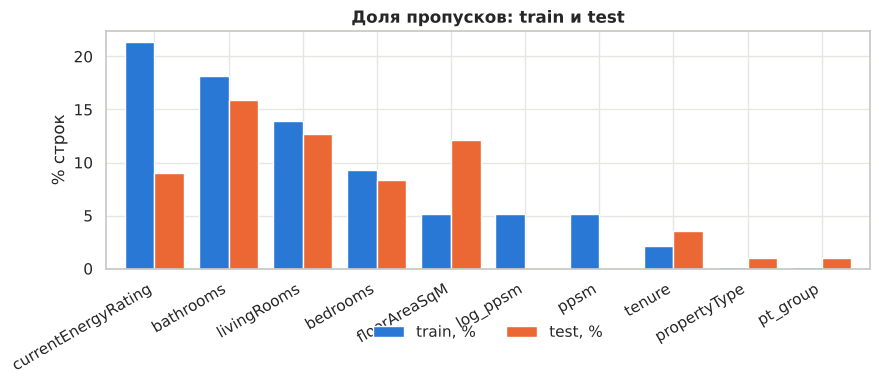

In [7]:
miss = pd.DataFrame({'train, %': train.isna().mean() * 100, 'test, %': test.isna().mean() * 100})
miss = miss[(miss > 0).any(axis=1)].sort_values('train, %', ascending=False)
miss['train, шт.'] = train.isna().sum()[miss.index]
display(miss.round(2))

ax = miss[['train, %', 'test, %']].plot.bar(figsize=(9, 4), color=[BLUE, ORANGE], width=0.8)
ax.set_title('Доля пропусков: train и test'); ax.set_ylabel('% строк'); ax.set_xlabel('')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

> **Что за график.** Для каждого столбца с пропусками показана доля пустых ячеек: синий — train, оранжевый — test.
> **Что показывает.** Больше всего пропусков в энергоклассе, ванных, гостиных, спальнях и площади. В test площадь пропущена заметно чаще, чем в train, а энергокласс реже. Значит, пропуски в test устроены немного иначе, и это нужно учитывать при заполнении.

**Насколько данные разрежены в целом.** Выше пропуски по каждому столбцу. Теперь посмотрим на всю таблицу: какая доля ячеек пустая и у какой доли строк есть хотя бы один пропуск.

In [8]:
raw_cols = list(test.columns) + ['price']          # только исходные столбцы, без вспомогательных
cells = train[raw_cols].size
empty = int(train[raw_cols].isna().sum().sum())
row_any = train[raw_cols].isna().any(axis=1).mean() * 100
n_miss = train[raw_cols].isna().sum(axis=1).value_counts().sort_index()
print(f'Пустых ячеек в train: {empty:,} из {cells:,} ({empty / cells * 100:.1f}%)'.replace(',', ' '))
print(f'Строк хотя бы с одним пропуском: {row_any:.1f}% (в test: {test.isna().any(axis=1).mean() * 100:.1f}%)')
display((n_miss / len(train) * 100).round(1).rename('доля строк, %').rename_axis('пропусков в строке').to_frame().T)

Пустых ячеек в train: 187 719 из 4 793 850 (3.9%)
Строк хотя бы с одним пропуском: 36.3% (в test: 30.8%)


пропусков в строке,0,1,2,3,4,5,6,7,8
"доля строк, %",63.700,19.500,6.300,6.200,2.200,1.900,0.000,0.200,0.000


**Вывод.** В целом таблица заполнена плотно: пустых ячеек всего 3,9%. Но пропуски сосредоточены в нескольких столбцах (энергокласс, комнаты, площадь), поэтому хотя бы один пропуск есть у 36% строк train и 31% строк test. Если удалять строки с пропусками, мы потеряем больше трети данных, поэтому пропуски заполняем (раздел 7.2).

### 3.1 Откуда берутся пропуски

Чтобы выбрать способ заполнения, проверим две вещи: связаны ли пропуски с типом жилья и пропускаются ли спальни, ванные и гостиные вместе.

,floorAreaSqM,bedrooms,bathrooms,livingRooms,currentEnergyRating,tenure,продаж
propertyType,,,,,,,
Purpose Built Flat,0.010,0.020,0.130,0.050,0.210,0.000,68726
Flat/Maisonette,0.150,0.300,0.370,0.380,0.290,0.080,61139
Mid Terrace House,0.000,0.030,0.120,0.070,0.160,0.000,45649
Converted Flat,0.020,0.020,0.130,0.050,0.260,0.000,32552
Semi-Detached House,0.010,0.030,0.120,0.070,0.130,0.000,20475
Terrace Property,0.040,0.000,0.050,0.060,0.170,0.000,15114
End Terrace House,0.010,0.030,0.110,0.070,0.140,0.000,13063
Detached House,0.040,0.040,0.130,0.090,0.150,0.000,6666
Terraced,0.610,0.630,0.710,0.710,0.550,0.010,927


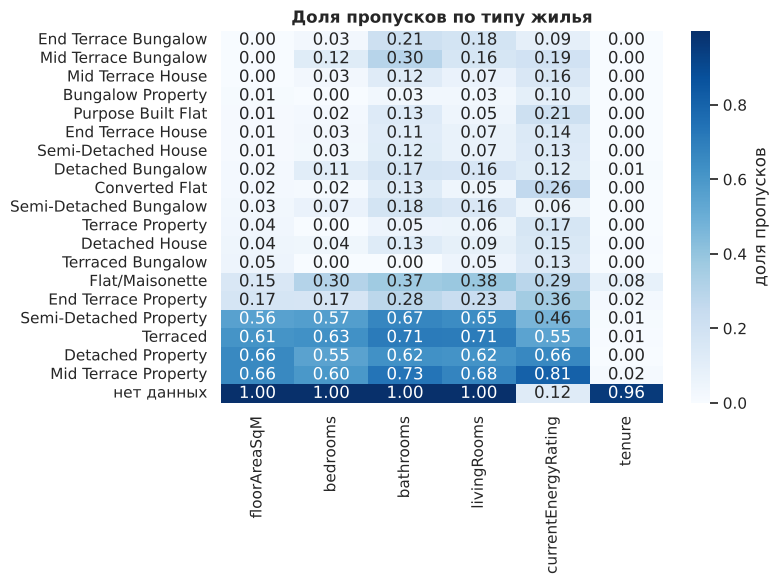

In [9]:
cols_m = ['floorAreaSqM', 'bedrooms', 'bathrooms', 'livingRooms', 'currentEnergyRating', 'tenure']
ptype = train['propertyType'].fillna('нет данных')
by_type = train.groupby(ptype)[cols_m].agg(lambda s: s.isna().mean())
by_type['продаж'] = ptype.value_counts()
display(by_type.sort_values('продаж', ascending=False).round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(by_type.drop(columns='продаж').sort_values('floorAreaSqM'), annot=True, fmt='.2f',
            cmap='Blues', cbar_kws={'label': 'доля пропусков'})
plt.title('Доля пропусков по типу жилья'); plt.ylabel(''); plt.tight_layout(); plt.show()

> **Что за график.** Тепловая карта: строки — названия типа жилья, столбцы — признаки, число в клетке — доля пропусков (чем темнее, тем больше).
> **Что показывает.** Пропуски сосредоточены в «редких» названиях типа (`Terraced`, `Detached Property`, `Semi-Detached Property` и других) и в `Flat/Maisonette`. У основных типов (`Purpose Built Flat`, `Mid Terrace House` и т.д.) площадь почти всегда известна.

In [10]:
three = ['bedrooms', 'bathrooms', 'livingRooms']
all3 = train[three].isna().all(axis=1).mean() * 100
print('Строк, где пропущены сразу спальни, ванные и гостиные: %.1f%%' % all3)
print('Если спальни пропущены, то ванные тоже пропущены в %.0f%% случаев (в среднем по всем строкам: %.0f%%)' %
      (train.loc[train.bedrooms.isna(), 'bathrooms'].isna().mean() * 100, train.bathrooms.isna().mean() * 100))
print('Строк без единого пропуска в 6 столбцах (площадь, комнаты, энергокласс, форма собственности): %.1f%%' %
      (train[cols_m].notna().all(axis=1).mean() * 100))

Строк, где пропущены сразу спальни, ванные и гостиные: 8.0%
Если спальни пропущены, то ванные тоже пропущены в 87% случаев (в среднем по всем строкам: 18%)
Строк без единого пропуска в 6 столбцах (площадь, комнаты, энергокласс, форма собственности): 63.7%


**Вывод.** Спальни, ванные и гостиные пропускаются обычно вместе (у них, скорее всего, общая причина), а площадь чаще пропущена у редких названий типа жилья.

### 3.2 Как заполнять площадь

Проверим на данных, насколько точно можно восстановить площадь. Скроем случайные 10% известных значений, заполним их тремя способами и посмотрим на среднюю ошибку (MAE, в м²).

In [11]:
known = train[train['floorAreaSqM'].notna() & train['bedrooms'].notna() & train['pt_group'].notna()].copy()
rng = np.random.RandomState(RANDOM_STATE)
mask = rng.rand(len(known)) < 0.10
tr_k, va_k = known[~mask], known[mask].copy()

med_t = tr_k.groupby('pt_group')['floorAreaSqM'].median().rename('p_type')
med_tb = tr_k.groupby(['pt_group', 'bedrooms'])['floorAreaSqM'].median().rename('p_type_bed')
va_k = va_k.join(med_t, on='pt_group').join(med_tb, on=['pt_group', 'bedrooms'])
va_k['p_glob'] = tr_k['floorAreaSqM'].median()

res = pd.Series({
    'одна медиана на всех': (va_k['floorAreaSqM'] - va_k['p_glob']).abs().mean(),
    'медиана по типу жилья': (va_k['floorAreaSqM'] - va_k['p_type']).abs().mean(),
    'медиана по типу и числу спален': (va_k['floorAreaSqM'] - va_k['p_type_bed'].fillna(va_k['p_type'])).abs().mean(),
}, name='средняя ошибка, м²')
display(res.to_frame().round(1))

,"средняя ошибка, м²"
одна медиана на всех,37.800
медиана по типу жилья,28.800
медиана по типу и числу спален,19.400


**Что делаем с пропусками** (реализовано в `src/clean.py`, результат в разделе 7.2):

- **Площадь:** заполняем медианой по типу жилья и числу спален (самая маленькая ошибка из трёх способов) и добавляем столбец-флаг «площадь была пропущена», потому что в test пропусков площади больше.
- **Спальни, ванные, гостиные:** заполняем медианой по типу жилья и тоже добавляем флаги. Для градиентного бустинга пропуски можно и не заполнять: он умеет с ними работать.
- **Энергокласс, форма собственности, тип жилья:** отдельная категория «неизвестно».
- **Строки с пропусками не удаляем:** их слишком много (больше трети строк).
- **Исходные столбцы не меняем:** заполненные значения записываем в новые столбцы `*_filled`. Для градиентного бустинга можно взять исходные столбцы с пропусками, для других моделей — заполненные.

## 4. Ошибки в данных

### 4.1 Тип жилья: одно и то же названо по-разному

In [12]:
pt = train.groupby(train['propertyType'].fillna('нет данных')).agg(
    продаж=('price', 'size'), медиана_площади=('floorAreaSqM', 'median'),
    доля_без_площади=('floorAreaSqM', lambda s: s.isna().mean()), медиана_цены=('price', 'median'))
pt['группа'] = pt.index.map(lambda x: PT_GROUP.get(x, 'нет данных'))
display(pt.sort_values(['группа', 'продаж'], ascending=[True, False]).round(2))

rare = ['Terraced', 'Mid Terrace Property', 'Semi-Detached Property', 'Detached Property',
        'End Terrace Property', 'Bungalow Property']
sh = train['propertyType'].isin(rare).groupby(train['sale_year']).mean() * 100
print('Доля продаж с редкими названиями типа, %%: 1995-2022 годы %.1f-%.1f, в 2023 году %.1f' %
      (sh.loc[:2022].min(), sh.loc[:2022].max(), sh.loc[2023]))

,продаж,медиана_площади,доля_без_площади,медиана_цены,группа
propertyType,,,,,
Bungalow Property,267,89.000,0.010,"425,000.000",Bungalow
Semi-Detached Bungalow,232,83.500,0.030,"365,000.000",Bungalow
Detached Bungalow,186,108.500,0.020,"522,500.000",Bungalow
Mid Terrace Bungalow,67,91.000,0.000,"347,500.000",Bungalow
Terraced Bungalow,38,83.000,0.050,"475,000.000",Bungalow
End Terrace Bungalow,33,74.000,0.000,"420,000.000",Bungalow
Detached House,6666,177.000,0.040,"865,000.000",Detached
Detached Property,160,122.000,0.660,"1,140,000.000",Detached
End Terrace House,13063,113.000,0.010,"450,000.000",End terrace


Доля продаж с редкими названиями типа, %: 1995-2022 годы 0.3-0.8, в 2023 году 1.2


В столбце `propertyType` 19 разных названий, но по смыслу это всего 6 типов: квартира, рядный дом, торцевой дом, дом на две семьи, отдельный дом, бунгало. Например, `Mid Terrace House` и `Terrace Property` — одно и то же. В таблице выше видно, как мы их объединили (столбец «группа»). Редкие названия, скорее всего, пришли из другого источника записей: у них много пропусков площади.

### 4.2 Форма собственности и дубликаты

In [13]:
display(train['tenure'].value_counts(dropna=False).to_frame('продаж').T)

dup_full = train.drop(columns='ID').duplicated().sum()
dup_addr_month = train.duplicated(['fullAddress', 'sale_year', 'sale_month']).sum()
dup_same = train.duplicated(['fullAddress', 'sale_year', 'sale_month', 'price']).sum()
print(f'Полных дубликатов (без ID): {dup_full}')
print(f'Повторов «адрес + месяц»: {dup_addr_month}, из них с той же ценой: {dup_same}, с другой ценой: {dup_addr_month - dup_same}')
ex = train[train.duplicated(['fullAddress', 'sale_year', 'sale_month'], keep=False)].sort_values(
    ['fullAddress', 'sale_year', 'sale_month']).head(6)
display(ex[['ID', 'fullAddress', 'sale_year', 'sale_month', 'price', 'floorAreaSqM', 'bedrooms']])

tenure,Leasehold,Freehold,NaN,Feudal,Shared
продаж,155910,102096,5721,1906,692


Полных дубликатов (без ID): 602
Повторов «адрес + месяц»: 1591, из них с той же ценой: 602, с другой ценой: 989


,ID,fullAddress,sale_year,sale_month,price,floorAreaSqM,bedrooms
242411,242411,"1 Alvington Crescent, London, E8 2NN",2023,5,720000,NaN,4.000
242412,242412,"1 Alvington Crescent, London, E8 2NN",2023,5,670000,NaN,4.000
221955,221955,"1 Alwyn Gardens, London, W3 0JH",2022,8,600000,98.000,3.000
221956,221956,"1 Alwyn Gardens, London, W3 0JH",2022,8,600000,98.000,3.000
80783,80783,"1 Ardgowan Road, London, SE6 1AJ",2006,4,340000,166.000,6.000
80784,80784,"1 Ardgowan Road, London, SE6 1AJ",2006,4,340000,166.000,6.000


Значения `Feudal` и `Shared` в форме собственности встречаются редко и необычны; их смысл по данным не ясен, поэтому оставим их как отдельные категории. Полные дубликаты можно удалять. Повторы «адрес + месяц» с разной ценой выглядят как опечатки в цене или как разные сделки, их надо проверять отдельно.

### 4.3 Подозрительные значения

In [14]:
a = train['floorAreaSqM']
checks = pd.Series({
    'площадь ровно 10 м²': int((a == 10).sum()),
    'площадь 499 м² и больше': int((a >= 499).sum()),
    'квартира больше 300 м²': int(((train.pt_group == 'Flat') & (a > 300)).sum()),
    'цена меньше 20 000 £': int((train.price < 20000).sum()),
    'цена 20 млн £ и больше': int((train.price >= 20_000_000).sum()),
}, name='строк')
display(checks.to_frame())

show = ['fullAddress', 'sale_year', 'price', 'floorAreaSqM', 'ppsm']
print('Самая высокая цена за м²:'); display(train.nlargest(3, 'ppsm')[show].round(0))
print('Самая низкая цена за м²:'); display(train.nsmallest(3, 'ppsm')[show].round(0))

print('country:', train.country.unique().tolist(), '(одно и то же значение, информации не несёт)')
print('Уникальных пар координат: %d, адресов: %d. Строк, у которых координаты такие же, как у другой строки: %.0f%%' %
      (train[['latitude', 'longitude']].drop_duplicates().shape[0], train.fullAddress.nunique(),
       train.duplicated(['latitude', 'longitude'], keep=False).mean() * 100))

,строк
площадь ровно 10 м²,12
площадь 499 м² и больше,18
квартира больше 300 м²,414
цена меньше 20 000 £,313
цена 20 млн £ и больше,158


Самая высокая цена за м²:


,fullAddress,sale_year,price,floorAreaSqM,ppsm
204253,"33 Summerfield Street, London, SE12 0NH",2021,99238058,45.000,"2,205,290.000"
125129,"Flat 2, Aldersgate Court, 30 Bartholomew Close...",2013,64000000,39.000,"1,641,026.000"
129805,"Flat 107, Tower House, 81 Fieldgate Street, Lo...",2014,60000000,44.000,"1,363,636.000"


Самая низкая цена за м²:


,fullAddress,sale_year,price,floorAreaSqM,ppsm
198312,"Flat 7, 49 Grosvenor Square, London, W1K 3EP",2021,22700,460.000,49.000
226729,"52 Coalecroft Road, London, SW15 6LP",2022,11270,209.000,54.000
215013,"19 Grove Park, London, E11 2DN",2022,12000,214.000,56.000


country: ['England'] (одно и то же значение, информации не несёт)


Уникальных пар координат: 84380, адресов: 118345. Строк, у которых координаты такие же, как у другой строки: 91%


Площадь ровно 10 м² (12 строк) и 499–500 м² (18 строк) встречается небольшими группами, возможно, значения обрезаны по границам. Есть и явные ошибки в цене: например, около 99 млн £ за квартиру в 45 м² или около 11 тысяч £ за дом в 209 м². Часть очень низких цен может быть настоящей (доли собственности, сделки между родственниками). Координаты у большинства строк совпадают с координатами других строк, то есть они, по-видимому, приблизительные (на уровне здания или улицы).

`country` всегда `England`, этот столбец бесполезен.

## 5. Выбросы

Выброс — значение, которое сильно отличается от большинства. Это не всегда ошибка: дорогие квартиры в центре Лондона настоящие, просто их мало.

,нижняя граница,верхняя граница,"выбросов, шт.","доля, %"
величина,,,,
цена,"-433,750.000","1,300,250.000",21280,7.990
log(цена),10.640,15.030,6791,2.550
площадь,-19.500,200.500,14221,5.630


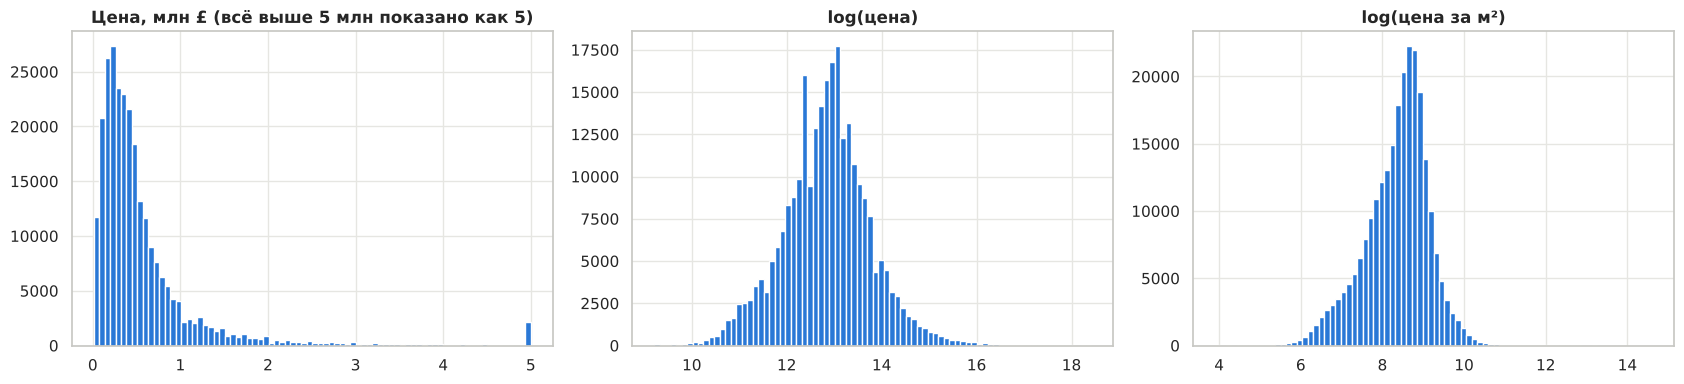

Цена за м² меньше 300 £: 513 строк, больше 40 000 £: 508 строк (всего 1021, 0.40%)


In [15]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

rows = []
for name, s in [('цена', train.price), ('log(цена)', train.log_price), ('площадь', train.floorAreaSqM)]:
    s = s.dropna(); lo, hi = iqr_bounds(s)
    rows.append({'величина': name, 'нижняя граница': lo, 'верхняя граница': hi,
                 'выбросов, шт.': int(((s < lo) | (s > hi)).sum()), 'доля, %': ((s < lo) | (s > hi)).mean() * 100})
display(pd.DataFrame(rows).set_index('величина').round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
(train.price / 1e6).clip(upper=5).plot.hist(bins=80, ax=axes[0], color=BLUE)
axes[0].set_title('Цена, млн £ (всё выше 5 млн показано как 5)'); axes[0].set_ylabel('')
train.log_price.plot.hist(bins=80, ax=axes[1], color=BLUE); axes[1].set_title('log(цена)'); axes[1].set_ylabel('')
train.log_ppsm.plot.hist(bins=80, ax=axes[2], color=BLUE); axes[2].set_title('log(цена за м²)'); axes[2].set_ylabel('')
plt.tight_layout(); plt.show()

low, high = (train.ppsm < 300).sum(), (train.ppsm > 40000).sum()
print(f'Цена за м² меньше 300 £: {low} строк, больше 40 000 £: {high} строк (всего {low + high}, {(low + high) / train.ppsm.notna().sum() * 100:.2f}%)')

> **Что за график.** Три гистограммы (чем выше столбец, тем больше продаж с такой ценой): цена в млн £ (всё дороже 5 млн показано как 5), логарифм цены и логарифм цены за м².
> **Что показывает.** У цены длинный «хвост» дорогих продаж: на обычной шкале график сильно перекошен вправо. После логарифма форма почти симметричная, поэтому модель удобнее обучать на логарифме цены.

**Что делаем с выбросами.** Дорогие продажи центральных районов не ошибки, их оставляем. Подозрительны только крайние значения цены за м² (меньше 300 £ или больше 40 000 £) и площадь на границах (10 и 500 м²). Такие строки не удаляем, а помечаем флагом и проверяем, как они влияют на качество модели.

## 6. Закономерности: что влияет на цену

### 6.1 Цены по годам

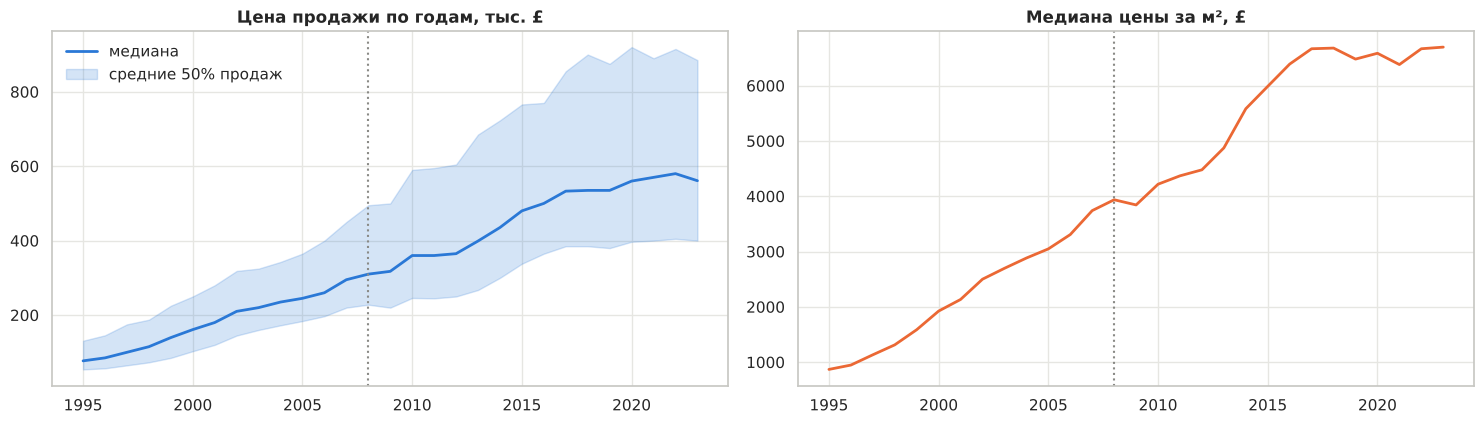

sale_year,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
медиана_цены,"77,000.000","85,000.000","100,000.000","115,000.000","139,500.000","161,000.000","179,950.000","210,000.000","220,000.000","235,000.000","245,000.000","260,000.000","295,000.000","310,000.000","317,500.000","360,000.000","360,000.000","365,000.000","398,950.000","435,250.000","480,000.000","500,000.000","533,000.000","535,000.000","535,000.000","560,000.000","570,000.000","580,000.000","561,000.000"
q25,"54,000.000","57,000.000","64,950.000","73,000.000","85,000.000","103,000.000","120,000.000","145,000.000","160,000.000","172,500.000","184,000.000","197,000.000","220,000.000","228,000.000","220,000.000","246,000.000","245,000.000","249,950.000","267,408.500","300,000.000","338,013.800","365,000.000","385,000.000","385,000.000","380,000.000","397,000.000","400,000.000","405,000.000","400,000.000"
q75,"131,000.000","145,625.000","175,000.000","187,500.000","225,000.000","250,000.000","280,000.000","318,500.000","324,746.200","342,750.000","365,000.000","400,000.000","450,000.000","495,000.000","500,000.000","590,000.000","595,000.000","604,500.000","685,000.000","723,170.000","765,875.000","770,000.000","855,000.000","900,000.000","875,000.000","920,000.000","890,000.000","915,000.000","885,000.000"
медиана_за_м2,868.300,946.800,"1,132.500","1,312.500","1,586.200","1,923.100","2,133.300","2,499.900","2,696.500","2,882.400","3,047.600","3,306.700","3,740.000","3,936.200","3,842.600","4,217.200","4,368.800","4,477.600","4,873.900","5,582.400","5,987.000","6,389.600","6,666.700","6,678.800","6,479.600","6,585.100","6,381.000","6,666.700","6,696.400"
продаж,"4,578.000","5,856.000","7,233.000","7,083.000","8,470.000","7,476.000","7,836.000","8,565.000","7,078.000","7,695.000","6,782.000","8,641.000","8,632.000","4,123.000","3,875.000","5,205.000","5,259.000","5,547.000","7,319.000","8,280.000","8,270.000","8,003.000","8,108.000","8,577.000","8,702.000","9,625.000","19,766.000","26,332.000","33,409.000"
изм_цены_год_к_году_pct,NaN,10.400,17.600,15.000,21.300,15.400,11.800,16.700,4.800,6.800,4.300,6.100,13.500,5.100,2.400,13.400,0.000,1.400,9.300,9.100,10.300,4.200,6.600,0.400,0.000,4.700,1.800,1.800,-3.300


In [16]:
yr = train.groupby('sale_year').agg(медиана_цены=('price', 'median'), q25=('price', lambda s: s.quantile(.25)),
                                     q75=('price', lambda s: s.quantile(.75)),
                                     медиана_за_м2=('ppsm', 'median'), продаж=('price', 'size'))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].plot(yr.index, yr.медиана_цены / 1e3, color=BLUE, lw=2, label='медиана')
axes[0].fill_between(yr.index, yr.q25 / 1e3, yr.q75 / 1e3, color=BLUE, alpha=0.2, label='средние 50% продаж')
axes[0].set_title('Цена продажи по годам, тыс. £'); axes[0].legend(loc='upper left', frameon=False)
axes[1].plot(yr.index, yr.медиана_за_м2, color=ORANGE, lw=2)
axes[1].set_title('Медиана цены за м², £')
for ax in axes: ax.axvline(2008, color=GRAY, ls=':'); ax.set_xlabel('')
plt.tight_layout(); plt.show()
display(yr.assign(изм_цены_год_к_году_pct=yr.медиана_цены.pct_change() * 100).round(1).T)

> **Что за график.** Слева: медиана цены продажи по годам (линия) и диапазон, в который попадает средняя половина продаж (полоса). Справа: медиана цены за м². Пунктир — 2008 год.
> **Что показывает.** Медиана цены выросла с 77 до 561 тыс. £. Цена за м² с 2017 года почти не растёт, а в 2023 году медиана цены на 3,3% ниже, чем в 2022. В 2008–2009 годах число продаж упало вдвое (4 123 и 3 875 против 8 632 в 2007), а после 2020 года сильно выросло (9 625 в 2020 и 33 409 в 2023; причина по данным не ясна).

### 6.2 Площадь и цена

Проверим идею: «чем больше площадь, тем ниже цена за м²». Смотрим продажи 2019–2023 годов отдельно для квартир, рядных и полуотдельных домов.

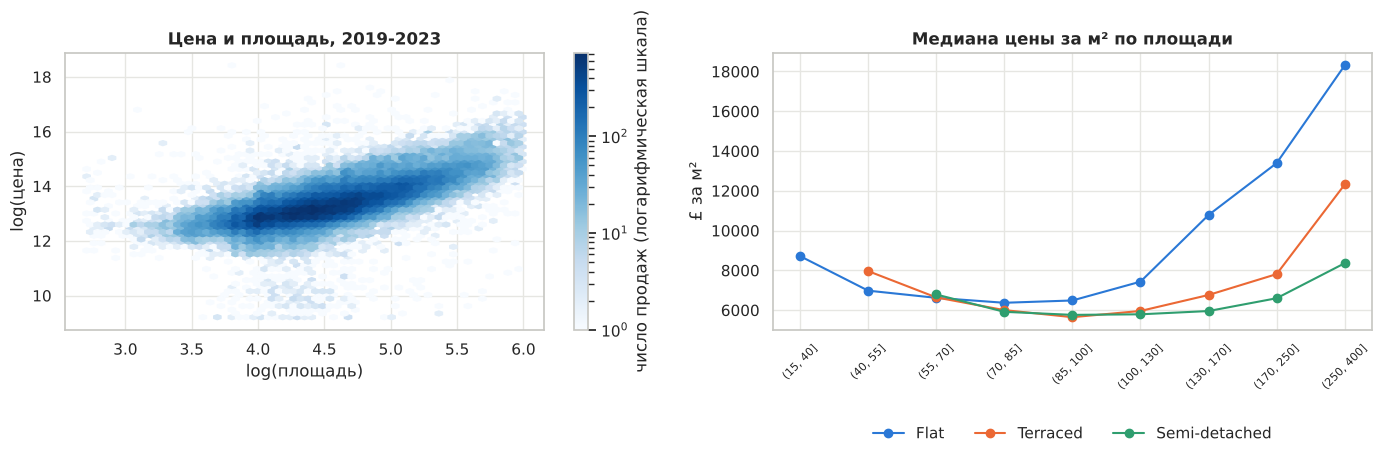

pt_group,Flat,Semi-detached,Terraced
area_bin,,,
"(15, 40]","8,714.000",NaN,NaN
"(40, 55]","6,978.000",NaN,"7,962.000"
"(55, 70]","6,618.000","6,786.000","6,639.000"
"(70, 85]","6,369.000","5,914.000","6,000.000"
"(85, 100]","6,485.000","5,761.000","5,645.000"
"(100, 130]","7,431.000","5,789.000","5,957.000"
"(130, 170]","10,784.000","5,954.000","6,761.000"
"(170, 250]","13,393.000","6,597.000","7,811.000"
"(250, 400]","18,308.000","8,359.000","12,317.000"


In [17]:
recent = train[(train.sale_year >= 2019) & train.floorAreaSqM.between(15, 400) & train.pt_group.notna()].copy()
recent['area_bin'] = pd.cut(recent.floorAreaSqM, [15, 40, 55, 70, 85, 100, 130, 170, 250, 400])
types3 = ['Flat', 'Terraced', 'Semi-detached']
tab = recent[recent.pt_group.isin(types3)].groupby(['area_bin', 'pt_group'])['ppsm'].agg(['median', 'size']).reset_index()
tab = tab[tab['size'] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
hb = axes[0].hexbin(np.log(recent.floorAreaSqM), recent.log_price, gridsize=60, bins='log', cmap='Blues', mincnt=1)
axes[0].set_xlabel('log(площадь)'); axes[0].set_ylabel('log(цена)'); axes[0].set_title('Цена и площадь, 2019-2023')
plt.colorbar(hb, ax=axes[0], label='число продаж (логарифмическая шкала)')
for t, col in zip(types3, [BLUE, ORANGE, '#2f9e6f']):
    d = tab[tab.pt_group == t]
    axes[1].plot(d.area_bin.astype(str), d['median'], marker='o', color=col, label=t)
axes[1].set_title('Медиана цены за м² по площади'); axes[1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1].set_ylabel('£ за м²')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

display(tab.pivot(index='area_bin', columns='pt_group', values='median').round(0))

> **Что за график.** Слева: логарифм цены против логарифма площади (чем темнее ячейка, тем больше продаж). Справа: медиана цены за м² для разных интервалов площади (линии — типы жилья; интервалы, где меньше 100 продаж, не показаны). Под графиком та же информация в таблице.
> **Что показывает.** Цена растёт вместе с площадью. А вот цена за м² строго с площадью не падает: у квартир она снижается до площади около 70–85 м², у домов до 85–100 м², а у более крупных объектов снова растёт (скорее всего, это дорогие объекты в центре и в престижных районах).
> **Осторожно.** На этот график влияет район: большие объекты чаще стоят в дорогих районах. Поэтому идею «больше площадь — ниже цена за м²» мы пока не подтвердили и не опровергли. Проверим её позже в модели, где можно отдельно учесть район и год.

### 6.3 Тип жилья, форма собственности, энергокласс, спальни

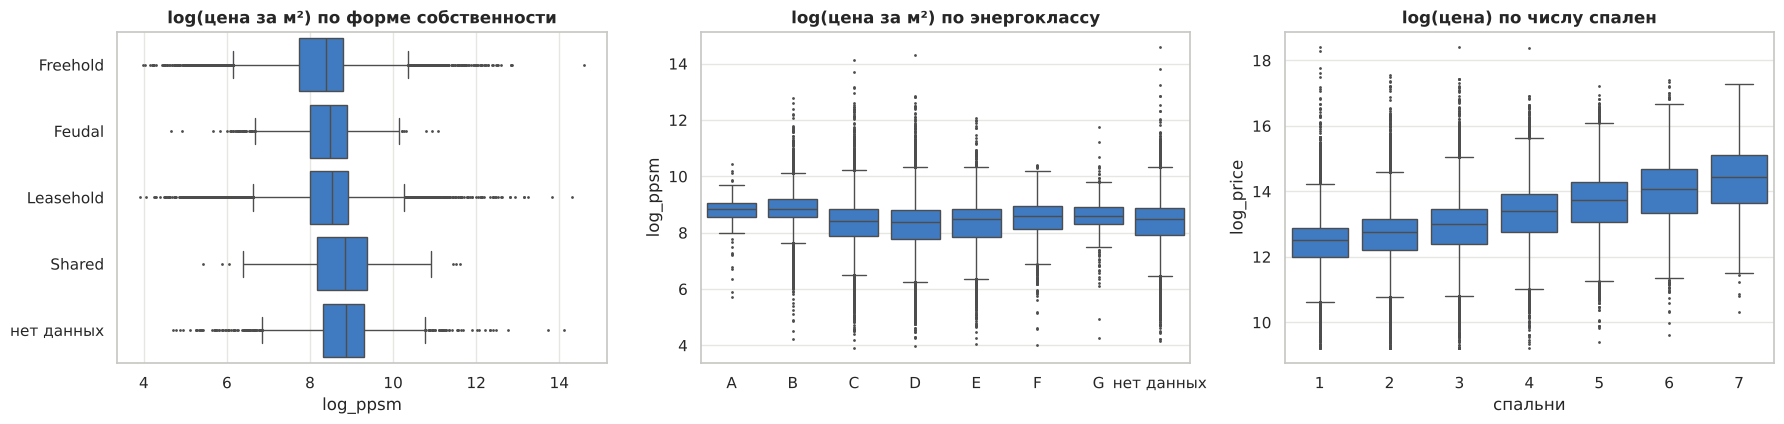

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
ten = train.assign(tenure=train.tenure.fillna('нет данных'))
order_t = ten.groupby('tenure').log_ppsm.median().sort_values().index
sns.boxplot(data=ten, y='tenure', x='log_ppsm', order=order_t, ax=axes[0], color=BLUE, fliersize=1)
axes[0].set_title('log(цена за м²) по форме собственности'); axes[0].set_ylabel('')
er = train.assign(r=train.currentEnergyRating.fillna('нет данных'))
sns.boxplot(data=er, x='r', y='log_ppsm', order=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'нет данных'], ax=axes[1],
            color=BLUE, fliersize=1)
axes[1].set_title('log(цена за м²) по энергоклассу'); axes[1].set_xlabel('')
bd = train[train.bedrooms.between(1, 7)].assign(bedrooms=lambda d: d.bedrooms.astype(int))
sns.boxplot(data=bd, x='bedrooms', y='log_price', ax=axes[2], color=BLUE, fliersize=1)
axes[2].set_title('log(цена) по числу спален'); axes[2].set_xlabel('спальни')
plt.tight_layout(); plt.show()

> **Что за график.** Три «ящика с усами». Ящик — средние 50% значений, черта внутри — медиана, точки — редкие необычные значения. Слева и в центре: логарифм цены за м² по форме собственности и по энергоклассу. Справа: логарифм цены по числу спален (от 1 до 7).
> **Что показывает.** По форме собственности различия в цене за м² небольшие. По энергоклассу тоже, но классы A и B заметно дороже остальных. Цена заметно растёт с числом спален: медиана от 270 тыс. £ (1 спальня) до 1,85 млн £ (7 спален).

**Сводные таблицы.** Как цена за м² зависит сразу от двух признаков: типа жилья и периода продажи, типа жилья и формы собственности. Берём только продажи с правдоподобной ценой за м² (от 300 до 40 000 £).

In [19]:
pv_src = train[train.ppsm.between(300, 40000) & train.pt_group.notna()].copy()
pv_src['период'] = pd.cut(pv_src.sale_year, [1994, 2007, 2015, 2023], labels=['1995-2007', '2008-2015', '2016-2023'])
order_pt = ['Flat', 'Terraced', 'End terrace', 'Semi-detached', 'Detached', 'Bungalow']
t1 = pv_src.pivot_table(index='pt_group', columns='период', values='ppsm', aggfunc='median', observed=True).reindex(order_pt)
t1['рост, раз'] = t1['2016-2023'] / t1['1995-2007']
print('Медиана цены за м², £: тип жилья и период')
display(t1.round({c: 0 for c in t1.columns[:3]} | {'рост, раз': 2}))
recent_pv = pv_src[pv_src.sale_year >= 2019]
t2 = recent_pv.pivot_table(index='pt_group', columns=recent_pv.tenure.fillna('нет данных'), values='ppsm',
                           aggfunc='median', observed=True).reindex(order_pt)
cnt = recent_pv.pivot_table(index='pt_group', columns=recent_pv.tenure.fillna('нет данных'), values='ppsm',
                            aggfunc='size', observed=True).reindex(order_pt)
print('Медиана цены за м², £, продажи 2019-2023: тип жилья и форма собственности (пусто: меньше 30 продаж)')
display(t2.where(cnt >= 30).round(0))

Медиана цены за м², £: тип жилья и период


период,1995-2007,2008-2015,2016-2023,"рост, раз"
pt_group,,,,
Flat,"2,631.000","5,303.000","6,875.000",2.610
Terraced,"1,859.000","4,138.000","6,259.000",3.370
End terrace,"1,774.000","3,854.000","5,825.000",3.280
Semi-detached,"1,804.000","3,882.000","6,035.000",3.350
Detached,"2,090.000","4,752.000","7,129.000",3.410
Bungalow,"2,183.000","4,552.000","6,391.000",2.930


Медиана цены за м², £, продажи 2019-2023: тип жилья и форма собственности (пусто: меньше 30 продаж)


tenure,Feudal,Freehold,Leasehold,Shared,нет данных
pt_group,,,,,
Flat,"7,000.000","5,994.000","6,800.000","10,439.000","8,384.000"
Terraced,NaN,"6,333.000","7,045.000",NaN,"6,138.000"
End terrace,NaN,"5,939.000","6,284.000",NaN,NaN
Semi-detached,NaN,"6,120.000","6,158.000",NaN,NaN
Detached,NaN,"7,214.000","7,643.000",NaN,NaN
Bungalow,NaN,"6,504.000",NaN,NaN,NaN


**Вывод.**

- За 1995–2023 годы цена за м² выросла примерно в 3 раза у всех типов жилья. У квартир рост меньше (в 2,6 раза), у домов больше (в 3,3–3,4 раза). В 1995–2007 годах м² квартиры стоил заметно дороже, чем м² дома (2 631 £ против 1 800–2 100 £), а в 2016–2023 годах разница почти исчезла.
- В 2019–2023 годах у одного и того же типа жилья м² в leasehold немного дороже, чем во freehold. Возможная причина: leasehold чаще встречается ближе к центру (это гипотеза, тут не проверена). Редкие формы `Shared` и «нет данных» у квартир дают высокую цену за м², но таких продаж мало.
- Оговорка: в таблицах смешаны разные районы. Например, квартир в центре больше, поэтому разница между типами частично объясняется местом, а не самим типом.

### 6.4 География

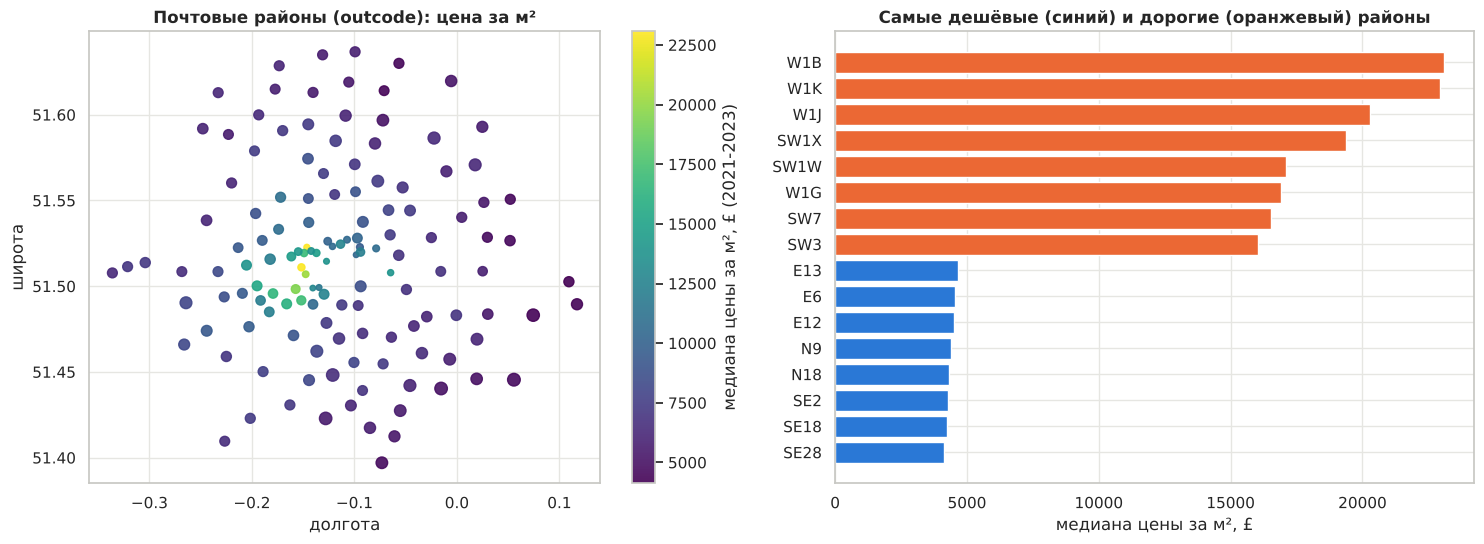

Медиана цены за м² по районам (2021-2023): от 4124 до 23076 £ (в 5.6 раза)


In [20]:
oc = train[train.sale_year >= 2021].groupby('outcode').agg(ppsm=('ppsm', 'median'), n=('price', 'size'),
                                                          lat=('latitude', 'median'), lon=('longitude', 'median'))
oc = oc[oc.n >= 50]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
sc = axes[0].scatter(oc.lon, oc.lat, c=oc.ppsm, s=np.sqrt(oc.n) * 2.2, cmap='viridis', alpha=0.9)
plt.colorbar(sc, ax=axes[0], label='медиана цены за м², £ (2021-2023)')
axes[0].set_title('Почтовые районы (outcode): цена за м²'); axes[0].set_xlabel('долгота'); axes[0].set_ylabel('широта')
top = pd.concat([oc.nlargest(8, 'ppsm'), oc.nsmallest(8, 'ppsm')]).sort_values('ppsm')
axes[1].barh(top.index, top.ppsm, color=[BLUE] * 8 + [ORANGE] * 8)
axes[1].set_title('Самые дешёвые (синий) и дорогие (оранжевый) районы'); axes[1].set_xlabel('медиана цены за м², £')
plt.tight_layout(); plt.show()
print('Медиана цены за м² по районам (2021-2023): от %.0f до %.0f £ (в %.1f раза)' %
      (oc.ppsm.min(), oc.ppsm.max(), oc.ppsm.max() / oc.ppsm.min()))

> **Что за график.** Слева карта почтовых районов (outcode): цвет — медиана цены за м² в 2021–2023 годах, размер точки — число продаж (показаны районы, где не меньше 50 продаж). Справа 8 самых дешёвых (синие) и 8 самых дорогих (оранжевые) районов.
> **Что показывает.** Цена за м² сильно зависит от района: от 4 124 £ (SE28) до 23 076 £ (W1B), то есть в 5,6 раза. Самые дорогие районы находятся в центре (W1, SW1) и рядом с ним на западе (SW7, SW3), самые дешёвые на востоке и северо-востоке.

### 6.5 Корреляции

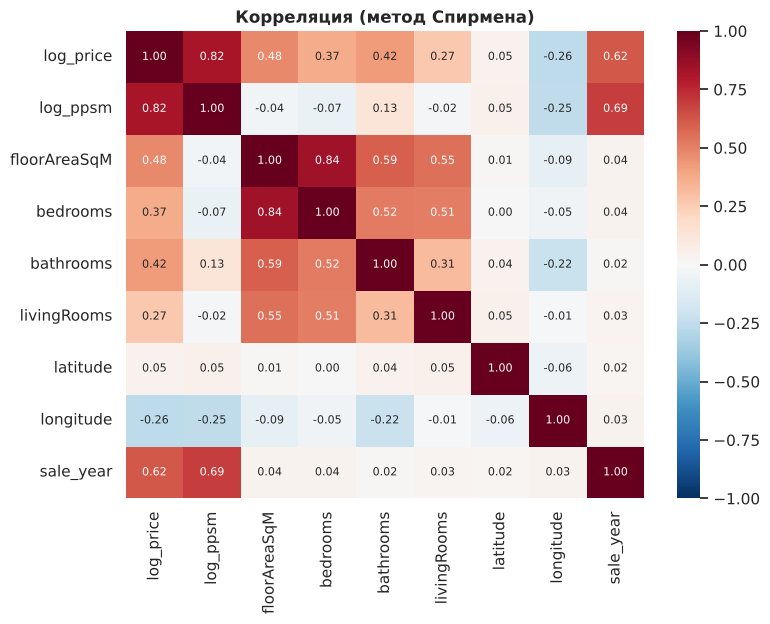

,log_ppsm,sale_year,floorAreaSqM,bathrooms,bedrooms,livingRooms,longitude,latitude
с log(цена),0.820,0.620,0.480,0.420,0.370,0.270,-0.260,0.050


In [21]:
cc = ['log_price', 'log_ppsm', 'floorAreaSqM', 'bedrooms', 'bathrooms', 'livingRooms', 'latitude', 'longitude', 'sale_year']
corr = train[cc].corr(method='spearman')
plt.figure(figsize=(8, 6.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Корреляция (метод Спирмена)'); plt.tight_layout(); plt.show()
display(corr['log_price'].drop('log_price').sort_values(key=abs, ascending=False).round(2).to_frame('с log(цена)').T)

> **Что за график.** Таблица корреляций между числовыми признаками: красный — признаки растут вместе, синий — один растёт, другой падает, белый — связи нет. Использован метод Спирмена, он ловит любую связь «больше — больше», не обязательно прямолинейную.
> **Что показывает.** Цена сильнее всего связана с годом продажи (0,62), площадью (0,48), числом ванных (0,42) и спален (0,37). С долготой связь отрицательная (−0,26: чем восточнее, тем дешевле), с широтой почти нулевая. Высокая корреляция цены и цены за м² (0,82) ожидаема: вторая считается из первой.

### 6.6 Повторные продажи одного адреса

Один и тот же адрес продаётся в разные годы. Цена предыдущей продажи этого же объекта может быть очень сильным признаком, но использовать можно только цены из прошлого.

Адресов в train: 118345; продавались больше одного раза: 64.1%
Строк, для которых есть предыдущая продажа того же адреса: 146389 (55.0% от train)
Корреляция log(цены) и log(предыдущей цены): 0.79


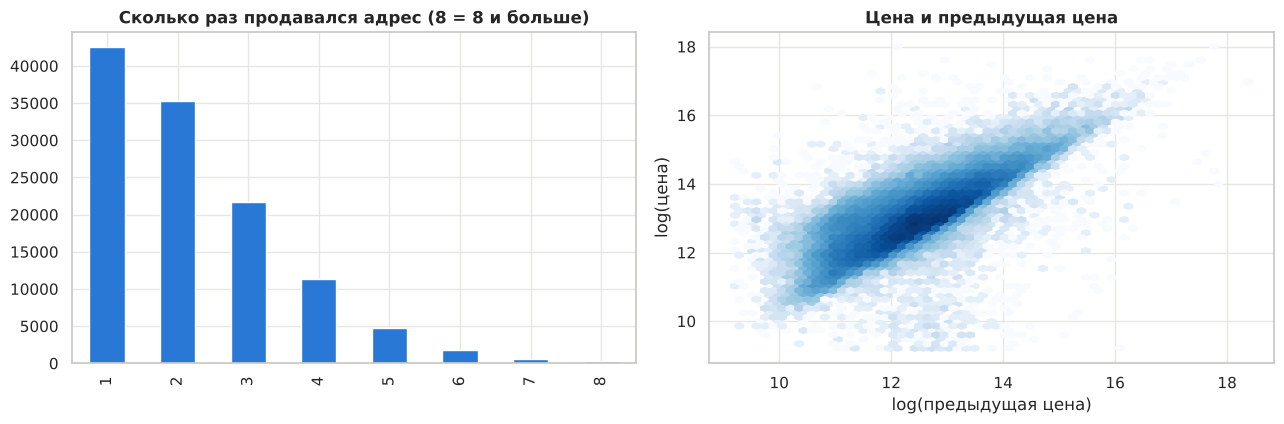

In [22]:
t = train.sort_values(['fullAddress', 'sale_year', 'sale_month']).copy()
t['t'] = t.sale_year * 12 + t.sale_month
g = t.groupby('fullAddress')
t['prev_price'] = g['price'].shift(); t['prev_t'] = g['t'].shift()
rep = t[(t['t'] - t['prev_t']) > 0].copy()

n_sales = train.groupby('fullAddress').size()
print(f'Адресов в train: {len(n_sales)}; продавались больше одного раза: {(n_sales > 1).mean() * 100:.1f}%')
print(f'Строк, для которых есть предыдущая продажа того же адреса: {len(rep)} ({len(rep) / len(train) * 100:.1f}% от train)')
print('Корреляция log(цены) и log(предыдущей цены): %.2f' % spearmanr(np.log(rep.price), np.log(rep.prev_price))[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
n_sales.clip(upper=8).value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE)
axes[0].set_title('Сколько раз продавался адрес (8 = 8 и больше)'); axes[0].set_xlabel('')
hb = axes[1].hexbin(np.log(rep.prev_price), np.log(rep.price), gridsize=60, bins='log', cmap='Blues', mincnt=1)
axes[1].set_xlabel('log(предыдущая цена)'); axes[1].set_ylabel('log(цена)'); axes[1].set_title('Цена и предыдущая цена')
plt.tight_layout(); plt.show()

> **Что за график.** Слева: сколько раз каждый адрес встречается в train. Справа: логарифм цены против логарифма цены предыдущей продажи того же адреса (чем темнее, тем больше пар).
> **Что показывает.** Почти две трети адресов продавались больше одного раза. Точки на правом графике лежат вдоль диагонали (корреляция 0,79): цена очень похожа на цену прошлой продажи с поправкой на рост рынка.

### 6.7 Похожи ли train и test

Модели обучаются на train и применяются к test, поэтому важно, насколько они похожи.

In [23]:
seen_addr = test.fullAddress.isin(set(train.fullAddress)).mean()
seen_pc = test.postcode.isin(set(train.postcode)).mean()
seen_oc = test.outcode.isin(set(train.outcode)).mean()
print(f'Адреса из test, которые есть в train: {seen_addr * 100:.1f}% | почтовые индексы: {seen_pc * 100:.1f}% | outcode: {seen_oc * 100:.2f}%')

tr23 = train[train.sale_year == 2023]
comp = pd.DataFrame({
    'train 2023': [tr23.floorAreaSqM.median(), tr23.bedrooms.median(), (tr23.pt_group == 'Flat').mean() * 100,
                   tr23.floorAreaSqM.isna().mean() * 100, tr23.currentEnergyRating.isna().mean() * 100],
    'test 2024': [test.floorAreaSqM.median(), test.bedrooms.median(), (test.pt_group == 'Flat').mean() * 100,
                  test.floorAreaSqM.isna().mean() * 100, test.currentEnergyRating.isna().mean() * 100]},
    index=['медиана площади, м²', 'медиана числа спален', 'доля квартир, %', 'пропуски площади, %', 'пропуски энергокласса, %'])
display(comp.round(1))

Адреса из test, которые есть в train: 76.4% | почтовые индексы: 93.1% | outcode: 99.99%


,train 2023,test 2024
"медиана площади, м²",86.000,84.000
медиана числа спален,2.000,2.000
"доля квартир, %",58.400,58.000
"пропуски площади, %",5.600,12.100
"пропуски энергокласса, %",12.700,9.000


Состав test похож на train 2023 года: по типам жилья, площади и числу спален. Отличаются пропуски (в test больше пропусков площади и меньше пропусков энергокласса). Три четверти адресов из test уже встречались в train, поэтому история прошлых продаж пригодится.

## 7. Основная база: очистка и новые признаки

Разделы 2–6 описывают исходные таблицы. Для моделей мы собрали **основную базу**: исходные столбцы, флаги очистки и новые признаки. Она собирается одной командой из корня репозитория:

```
python src/build_dataset.py
```

Что делает скрипт:

1. **Очистка** (`src/clean.py`) по правилам разделов 3–5. Строки **не удаляем**, а помечаем флагами (0 или 1). Что выкинуть при обучении, решим на этапе моделей: так решение видно, и его легко поменять.
2. **Новые признаки** (`src/add_features.py`): прошлая продажа адреса, расстояния до центров, транспорт, плотность и цены соседей, район, индекс депривации IMD. Признаки из цен считаются **только по прошлому** и только по «чистым» строкам (без дубликатов и подозрительных цен), иначе одна ошибочная цена испортит признаки у всех соседей.
3. **Итоговый набор** (список `KEEP` в `src/build_dataset.py`): 15 признаков, отобранных проверкой (раздел 7.9).

Источники внешних данных и подробности расчёта описаны в `FEATURES.md`. Для этого раздела нужны таблицы из `data/processed` (в git их нет, они собираются командой выше).

### 7.1 Флаги очистки

| Флаг | Что значит |
|------|------------|
| `pt_group` | тип жилья, 19 названий сведены к 6 группам (раздел 4.1) |
| `is_duplicate` | полный дубликат строки; первая копия не помечается |
| `dup_addr_month` | у адреса несколько продаж в одном месяце с разной ценой (раздел 4.2) |
| `price_suspect` | цена за м² меньше 300 £ или больше 40 000 £ (раздел 5); только train |
| `area_suspect` | площадь ровно 10 м² или 499 м² и больше (раздел 4.3) |
| `addr_multi_unit` | под адресом, похоже, несколько квартир (раздел 7.3) |

In [24]:
PROCESSED_DIRS = ['data/processed', '../data/processed']
proc = next((Path(d) for d in PROCESSED_DIRS if (Path(d) / 'train_enriched.csv').exists()), None)
if proc is None:
    raise FileNotFoundError('Нет data/processed/train_enriched.csv. Соберите базу: python src/build_dataset.py '
                            '(из корня репозитория, нужны файлы из data/external, см. README.md, раздел «Данные»)')
tr_e = pd.read_csv(proc / 'train_enriched.csv', low_memory=False)
te_e = pd.read_csv(proc / 'test_enriched.csv', low_memory=False)
tr_f = pd.read_csv(proc / 'train_final.csv', low_memory=False)
print('Папка:', proc.resolve())
print('train_enriched:', tr_e.shape, '| test_enriched:', te_e.shape)
print('train_final:', tr_f.shape, '| столбцов-признаков в итоговом наборе:', 15)

FLAGS = ['is_duplicate', 'dup_addr_month', 'price_suspect', 'area_suspect', 'addr_multi_unit']
flags = pd.DataFrame({'train, строк': tr_e[FLAGS].sum(), 'train, %': tr_e[FLAGS].mean() * 100,
                      'test, строк': te_e[FLAGS].sum(), 'test, %': te_e[FLAGS].mean() * 100})
flags.index.name = 'флаг'
display(flags.round(2))
print('Строк train, по которым считаются признаки из цен (без дубликатов и подозрительных цен): %d из %d' %
      (((tr_e.is_duplicate == 0) & (tr_e.price_suspect == 0)).sum(), len(tr_e)))

Папка: /home/user/hse-ai-project/data/processed
train_enriched: (266325, 67) | test_enriched: (16547, 66)
train_final: (266325, 49) | столбцов-признаков в итоговом наборе: 15


,"train, строк","train, %","test, строк","test, %"
флаг,,,,
is_duplicate,602,0.230,60,0.360
dup_addr_month,1839,0.690,0,0.000
price_suspect,1021,0.380,0,0.000
area_suspect,30,0.010,2,0.010
addr_multi_unit,12761,4.790,541,3.270


Строк train, по которым считаются признаки из цен (без дубликатов и подозрительных цен): 264707 из 266325


**Вывод.** Флагами помечено немного строк, сильнее всего `addr_multi_unit` (около 5%). Для признаков из цен исключены 1 618 строк train (дубликаты и подозрительные цены, часть строк попадает в обе группы). В test тоже нашлись 60 полных дубликатов: это одинаковые строки без цены, при предсказании их можно оставить.

### 7.2 Заполнение пропусков

Правила взяты из раздела 3 (там же проверено, какой способ заполнения площади точнее):

| Столбец | Чем заполняем | Почему |
|---------|---------------|--------|
| `floorAreaSqM` | медиана по типу жилья и числу спален; если спален нет — по типу жилья | самая маленькая ошибка в проверке раздела 3.2: 19 м² против 38 м² у одной медианы на всех |
| `bedrooms`, `bathrooms`, `livingRooms` | медиана по типу жилья | комнаты пропускаются вместе, и опереться можно только на тип |
| `tenure`, `currentEnergyRating`, `pt_group` | категория `Unknown` | категорию нельзя «усреднить», а сам пропуск может нести информацию |

Медианы считаются только по train (без подозрительных площадей), test их не видит. Исходные столбцы не меняются: заполненные значения лежат в столбцах `*_filled`, а флаги `*_missing` показывают, где значение было пропущено.

,"пропусков train, %","пропусков test, %",после заполнения (train+test),медиана до,медиана после
столбец,,,,,
floorAreaSqM,5.180,12.120,0,85.000,83.000
bedrooms,9.330,8.310,0,2.000,2.000
bathrooms,18.200,15.860,0,1.000,1.000
livingRooms,13.910,12.660,0,1.000,1.000
tenure,2.150,3.570,0,NaN,NaN
currentEnergyRating,21.330,9.050,0,NaN,NaN
pt_group,0.190,1.010,0,NaN,NaN


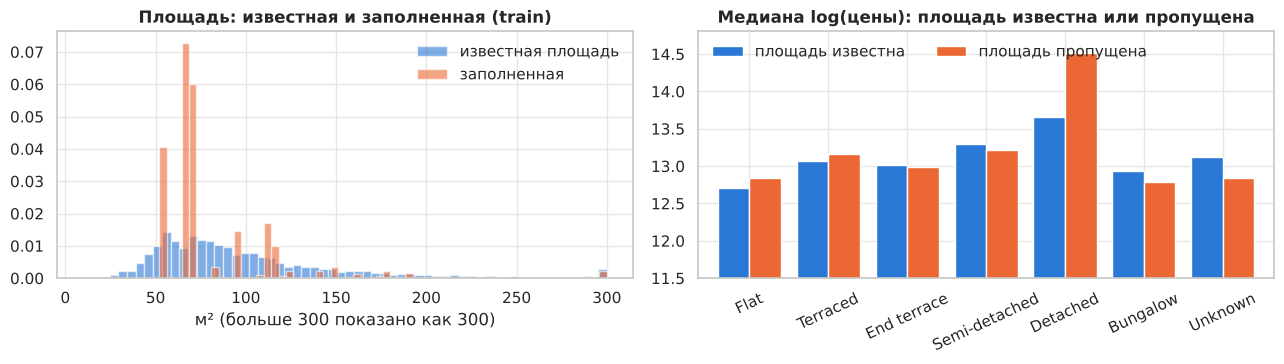

In [25]:
NUM_FILL = ['floorAreaSqM', 'bedrooms', 'bathrooms', 'livingRooms']
CAT_FILL = ['tenure', 'currentEnergyRating', 'pt_group']
rows = []
for c in NUM_FILL + CAT_FILL:
    rows.append({'столбец': c,
                 'пропусков train, %': tr_e[c].isna().mean() * 100, 'пропусков test, %': te_e[c].isna().mean() * 100,
                 'после заполнения (train+test)': int(tr_e[f'{c}_filled'].isna().sum() + te_e[f'{c}_filled'].isna().sum()),
                 'медиана до': tr_e[c].median() if c in NUM_FILL else np.nan,
                 'медиана после': tr_e[f'{c}_filled'].median() if c in NUM_FILL else np.nan})
display(pd.DataFrame(rows).set_index('столбец').round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
known = tr_e.loc[tr_e.floorAreaSqM_missing == 0, 'floorAreaSqM'].clip(upper=300)
filled = tr_e.loc[tr_e.floorAreaSqM_missing == 1, 'floorAreaSqM_filled'].clip(upper=300)
axes[0].hist(known, bins=60, density=True, color=BLUE, alpha=.6, label='известная площадь')
axes[0].hist(filled, bins=60, density=True, color=ORANGE, alpha=.6, label='заполненная')
axes[0].set_title('Площадь: известная и заполненная (train)'); axes[0].set_xlabel('м² (больше 300 показано как 300)')
axes[0].legend(frameon=False)
lp = np.log(tr_e.price)
m = tr_e[tr_e.price_suspect == 0].assign(lp=lp).groupby(['pt_group_filled', 'floorAreaSqM_missing']).lp.median().unstack()
m = m.reindex([p for p in order_pt + ['Unknown'] if p in m.index])
m.plot.bar(ax=axes[1], color=[BLUE, ORANGE], rot=25, width=.8)
axes[1].set_ylim(11.5, m.max().max() + 0.3); axes[1].set_title('Медиана log(цены): площадь известна или пропущена')
axes[1].set_xlabel(''); axes[1].legend(['площадь известна', 'площадь пропущена'], frameon=False, ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

> **Что за график.** Слева распределение площади в train: синий — известная площадь, оранжевый — заполненная. Справа медиана логарифма цены по типу жилья отдельно для строк, где площадь известна и где она была пропущена.
> **Что показывает.** Заполненные значения собираются в «пики» (одно значение на тип жилья и число спален): так всегда бывает при заполнении медианой. Модель получает типичную площадь, а флаг `floorAreaSqM_missing` подсказывает ей, что значение приблизительное. Для большинства типов жилья цены у строк с пропущенной площадью почти такие же, как у строк с известной: у квартир и рядных домов чуть выше, у бунгало и неизвестного типа чуть ниже. Исключение — отдельные дома (Detached): с пропущенной площадью они заметно дороже (медиана log(цены) 14,5 против 13,7, то есть примерно в 2,3 раза). Таких строк немного (399), возможно, это крупные дорогие дома, у которых нет записи о площади (гипотеза, не проверена). Значит, медиана для них занижает площадь, и флаг `floorAreaSqM_missing` нужен, чтобы модель могла это учесть.

**Вывод.** После заполнения пропусков не осталось ни в train, ни в test. Типичные значения почти не изменились (медиана площади 85 → 83 м²). В test площадь пропущена чаще (12% против 5%), поэтому флаг `floorAreaSqM_missing` особенно важен.

### 7.3 Адреса, под которыми несколько квартир

В разделе 6.6 мы видели, что один адрес иногда продаётся десятки раз. Одна квартира так часто не продаётся. Похоже, у части строк `fullAddress` — это адрес целого дома, и под ним скрыты разные квартиры. Площадь, спальни и другие характеристики у одного адреса всегда одинаковые, поэтому по ним такие адреса не отличить. Посмотрим, сколько месяцев проходит между продажами одного адреса и насколько при этом меняется цена.

,пар,"доля пар, %","медиана |изменения цены|, %"
интервал,,,
тот же месяц,989,0.700,18.300
1-3,2098,1.400,23.800
4-6,2158,1.500,30.100
7-12,4289,2.900,30.400
13-24,9337,6.300,27.700
25-60,38167,25.900,32.700
больше 60,90340,61.300,88.600


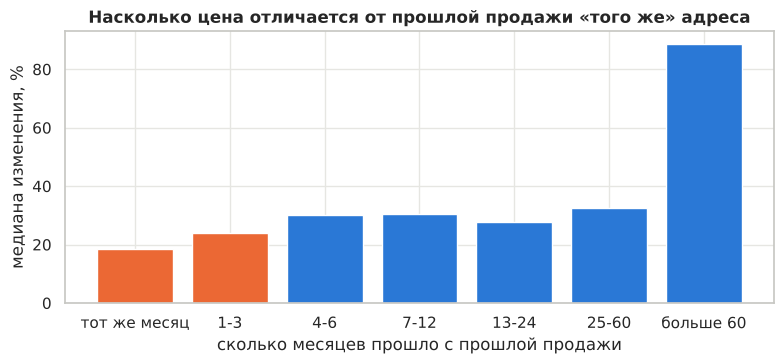

Больше всего продаж у адреса: 74 Western Beach Apartments, 36 Hanover Avenue, London, E16 1DZ - 112
Строк с флагом addr_multi_unit: train 4.8%, test 3.3%


In [26]:
d = train.drop_duplicates(train.columns.drop('ID')).copy()
d['t'] = d.sale_year * 12 + d.sale_month
d = d.sort_values(['fullAddress', 't'])
g = d.groupby('fullAddress')
d['gap'] = d['t'] - g['t'].shift()
d['jump'] = (np.log(d['price']) - np.log(g['price'].shift())).abs()
rep2 = d[d.gap.notna()].copy()
bins = [-1, 0, 3, 6, 12, 24, 60, 400]
labels = ['тот же месяц', '1-3', '4-6', '7-12', '13-24', '25-60', 'больше 60']
rep2['интервал'] = pd.cut(rep2.gap, bins, labels=labels)
tab = rep2.groupby('интервал', observed=True).agg(пар=('gap', 'size'), изменение_цены=('jump', 'median'))
tab['доля пар, %'] = tab['пар'] / tab['пар'].sum() * 100
tab['медиана |изменения цены|, %'] = (np.exp(tab['изменение_цены']) - 1) * 100
display(tab[['пар', 'доля пар, %', 'медиана |изменения цены|, %']].round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(tab.index.astype(str), tab['медиана |изменения цены|, %'], color=[ORANGE] * 2 + [BLUE] * 5)
ax.set_title('Насколько цена отличается от прошлой продажи «того же» адреса')
ax.set_xlabel('сколько месяцев прошло с прошлой продажи'); ax.set_ylabel('медиана изменения, %')
plt.tight_layout(); plt.show()

n_addr = train.groupby('fullAddress').size()
print('Больше всего продаж у адреса:', n_addr.idxmax(), '-', n_addr.max())
print('Строк с флагом addr_multi_unit: train %.1f%%, test %.1f%%' % (tr_e.addr_multi_unit.mean() * 100, te_e.addr_multi_unit.mean() * 100))

> **Что за график.** Для пар «продажа и предыдущая продажа того же адреса» показана медиана изменения цены в зависимости от того, сколько месяцев прошло между ними. Оранжевые столбцы — интервалы до 3 месяцев: такие адреса помечаем флагом.
> **Что показывает.** Даже когда между продажами прошло 1–3 месяца, цена обычно отличается на 24%, а внутри одного месяца на 18%. За такой срок цена одной квартиры почти не меняется, и так быстро квартиру почти не перепродают: одно оформление сделки занимает месяцы. Значит, в таких парах это, скорее всего, разные квартиры одного дома. При интервале 1–2 года цена тоже отличается заметно (около 28–30%): вероятно, разные квартиры под одним адресом есть и там, но их уже не отличить от настоящих перепродаж.

**Что делаем.** Помечаем флагом `addr_multi_unit` адреса, у которых есть две продажи с интервалом не больше 3 месяцев (в том числе в одном месяце). Флаг считается по датам продаж train и test, цены не используются. Строки не удаляем: модель сможет учесть, что прошлая цена у таких адресов менее надёжна (это видно в разделе 7.7).

### 7.4 Новые признаки: пропуски и типичные значения

В итоговый набор вошли 15 признаков из шести групп. Сколько в них пропусков и какие у них типичные значения?

In [27]:
GROUPS = {
    'прошлая продажа адреса': ['prev_sale_price', 'prev_price_adj', 'prev_sale_gap_months'],
    'расстояния до центров': ['dist_charing_cross_km', 'dist_canary_wharf_km', 'dist_nearest_centre_km', 'dist_subcentre_km'],
    'транспорт': ['dist_station_km', 'dist_tube_km'],
    'окружение': ['n_addr_500m', 'knn20_prev_med_logppsm'],
    'район': ['borough'],
    'индекс депривации IMD': ['imd_score', 'crime_decile', 'living_env_decile'],
}
rows = []
for grp, cols in GROUPS.items():
    for c in cols:
        rows.append({'группа': grp, 'признак': c,
                     'пропусков в train, %': tr_e[c].isna().mean() * 100,
                     'пропусков в test, %': te_e[c].isna().mean() * 100,
                     'медиана train': tr_e[c].median() if pd.api.types.is_numeric_dtype(tr_e[c]) else np.nan,
                     'медиана test': te_e[c].median() if pd.api.types.is_numeric_dtype(te_e[c]) else np.nan})
display(pd.DataFrame(rows).set_index(['группа', 'признак']).round(2))

пропусков в train, %  пропусков в test, %  медиана train  медиана test
группа                 признак                                                                                       
прошлая продажа адреса prev_sale_price                       44.850               23.690    250,000.000   395,000.000
                       prev_price_adj                        44.930               23.720    420,736.480   572,248.840
                       prev_sale_gap_months                  44.850               23.690         78.000       117.000
расстояния до центров  dist_charing_cross_km                  0.000                0.000          8.050         8.590
                       dist_canary_wharf_km                   0.000                0.000          9.320        10.170
                       dist_nearest_centre_km                 0.000                0.000          6.320         6.790
                       dist_subcentre_km                      0.000                0.000          1.580         1.590
транспорт              dist_station_km                        0.000                0.000          0.500         0.510
                       dist_tube_km                           0.000                0.000          0.940         0.950
окружение              n_addr_500m                            0.000                0.000        220.000       163.000
                       knn20_prev_med_logppsm                 1.720                0.000          8.500         8.820
район                  borough                                0.010                0.020            NaN           NaN
индекс депривации IMD  imd_score                              5.290                8.520         19.780        19.500
                       crime_decile                           5.290                8.520          4.000         4.000
                       living_env_decile                      5.290                8.520          2.000         3.000

**Вывод.**

- **Прошлая продажа** есть у 55% строк train и у 76% строк test: у test за спиной вся история train. Пропуск здесь означает «адрес раньше не продавался». Это тоже информация, заполнять такой пропуск не нужно.
- **IMD** пуст у 5,3% строк train и 8,5% строк test. Вероятная причина: postcodes.io выдаёт новые коды районов LSOA (перепись 2021 года), а IMD 2019 посчитан по кодам 2011 года, и часть кодов поменялась. Исправить можно таблицей соответствия кодов 2011 и 2021 годов от ONS (задача на будущее).
- **Цены соседей за прошлый год** пусты у 1,7% строк train: это все продажи 1995 года, для них в данных нет прошлого года.
- Расстояния, транспорт и район есть почти у всех строк.

### 7.5 Как новые признаки связаны с ценой

Берём продажи 2019–2023 годов без подозрительных цен. Делим продажи на 20 равных по численности групп по значению признака и для каждой группы считаем медиану цены за м².

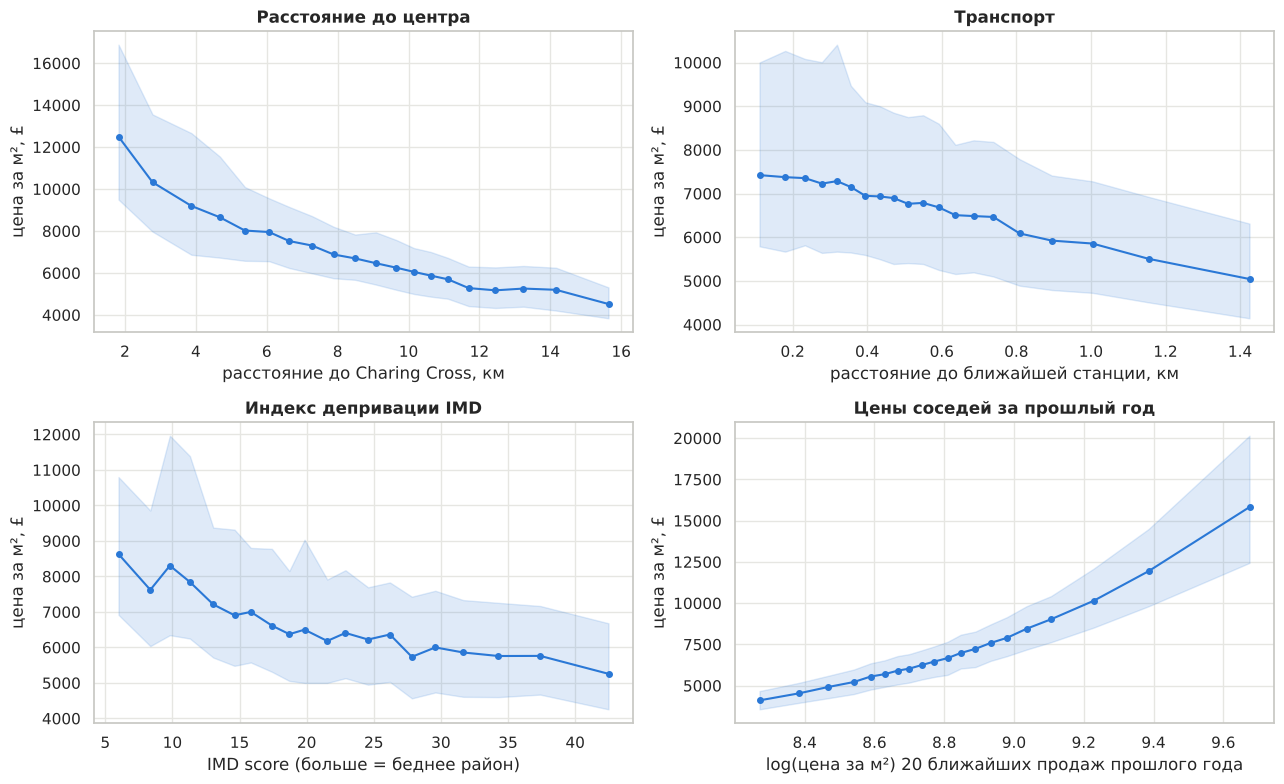

Корреляция Спирмена с log(цена за м²), продажи 2019-2023: до центра -0.60, до станции -0.25, IMD -0.32, цены соседей 0.74


In [28]:
recent = tr_e[(tr_e.sale_year >= 2019) & (tr_e.price_suspect == 0) & tr_e.floorAreaSqM.between(15, 400)].copy()
recent['log_ppsm'] = np.log(recent.price / recent.floorAreaSqM)

def binned(ax, col, q=20, xlabel=''):
    s = recent[[col, 'log_ppsm']].dropna()
    b = pd.qcut(s[col], q, duplicates='drop')
    m = s.groupby(b, observed=True).agg(x=(col, 'median'), y=('log_ppsm', 'median'),
                                        lo=('log_ppsm', lambda v: v.quantile(.25)), hi=('log_ppsm', lambda v: v.quantile(.75)))
    ax.fill_between(m.x, np.exp(m.lo), np.exp(m.hi), color=BLUE, alpha=.15)
    ax.plot(m.x, np.exp(m.y), 'o-', color=BLUE, ms=4)
    ax.set_xlabel(xlabel); ax.set_ylabel('цена за м², £')
    return spearmanr(s[col], s['log_ppsm'])[0]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
r1 = binned(axes[0, 0], 'dist_charing_cross_km', xlabel='расстояние до Charing Cross, км')
axes[0, 0].set_title('Расстояние до центра')
r2 = binned(axes[0, 1], 'dist_station_km', xlabel='расстояние до ближайшей станции, км')
axes[0, 1].set_title('Транспорт')
r3 = binned(axes[1, 0], 'imd_score', xlabel='IMD score (больше = беднее район)')
axes[1, 0].set_title('Индекс депривации IMD')
r4 = binned(axes[1, 1], 'knn20_prev_med_logppsm', xlabel='log(цена за м²) 20 ближайших продаж прошлого года')
axes[1, 1].set_title('Цены соседей за прошлый год')
plt.tight_layout(); plt.show()
print('Корреляция Спирмена с log(цена за м²), продажи 2019-2023: до центра %.2f, до станции %.2f, IMD %.2f, цены соседей %.2f'
      % (r1, r2, r3, r4))

> **Что за график.** Каждая точка — одна из 20 групп продаж, упорядоченных по признаку: по горизонтали медиана признака в группе, по вертикали медиана цены за м². Полоса показывает средние 50% цен в группе.
> **Что показывает.** Чем дальше от центра, тем дешевле м² (корреляция −0,60). Близость к станции тоже связана с ценой, но слабее (−0,25). Чем выше IMD, то есть чем беднее район, тем ниже цена (−0,32). Сильнее всего с ценой связаны цены соседей за прошлый год (0,74): они почти напрямую описывают уровень цен в этом месте.

Оговорка: признаки связаны и между собой (центр, транспорт и бедность района перемешаны), поэтому по отдельным графикам нельзя сказать, какой из них важнее для прогноза. Это проверяется абляцией (раздел 7.9).

### 7.6 Попарные распределения и корреляции

Посмотрим на главные признаки вместе: как каждый распределён и как пары признаков связаны между собой и с ценой. Для `pairplot` берём случайные 5 000 продаж 2019–2023 годов без подозрительных цен (на всех продажах график строится слишком долго и точки сливаются). Площадь и число спален — заполненные (`*_filled`).

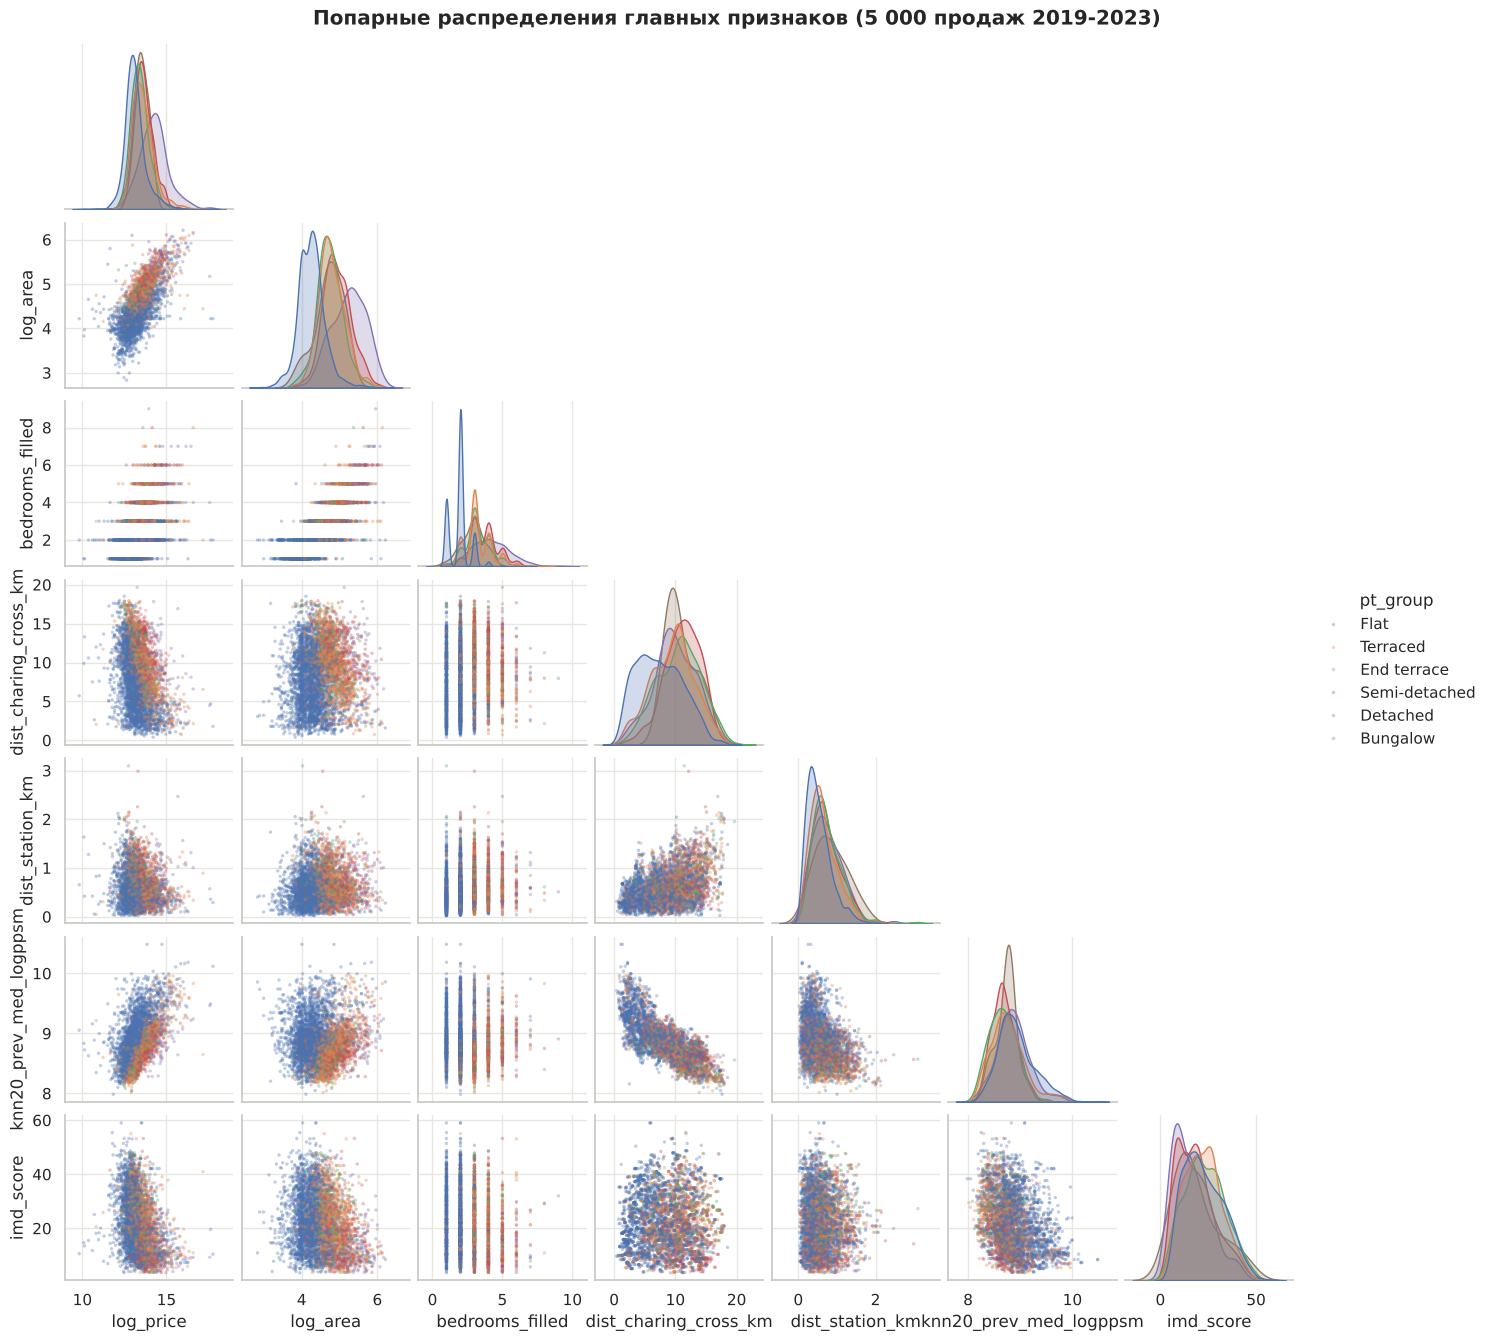

In [29]:
PAIR = ['log_price', 'log_area', 'bedrooms_filled', 'dist_charing_cross_km', 'dist_station_km',
        'knn20_prev_med_logppsm', 'imd_score']
pp = tr_e[(tr_e.sale_year >= 2019) & (tr_e.price_suspect == 0) & tr_e.pt_group.notna()].copy()
pp['log_price'] = np.log(pp.price)
pp['log_area'] = np.log(pp.floorAreaSqM_filled)
sample = pp.sample(5000, random_state=RANDOM_STATE)
g = sns.pairplot(sample[PAIR + ['pt_group']], hue='pt_group', hue_order=order_pt, corner=True,
                 plot_kws={'s': 6, 'alpha': .35, 'linewidth': 0}, diag_kind='kde', diag_kws={'common_norm': False},
                 height=1.9)
g.figure.suptitle('Попарные распределения главных признаков (5 000 продаж 2019-2023)', y=1.01, fontweight='bold')
plt.show()

> **Что за график.** На диагонали распределение каждого признака отдельно по типам жилья (цвет). Под диагональю точки для каждой пары признаков. `log_area` — логарифм площади, `knn20_prev_med_logppsm` — уровень цен 20 ближайших продаж прошлого года.
> **Что показывает.** Цена заметнее всего растёт с площадью и с ценами соседей. Квартиры (синие) меньше по площади и чаще расположены ближе к центру, дома дальше. Расстояние до центра и цены соседей сильно связаны: чем дальше от центра, тем дешевле соседи. Связь цены с IMD и с расстоянием до станции видна слабо, облако точек широкое. Спальни принимают несколько целых значений, поэтому выглядят как полосы.

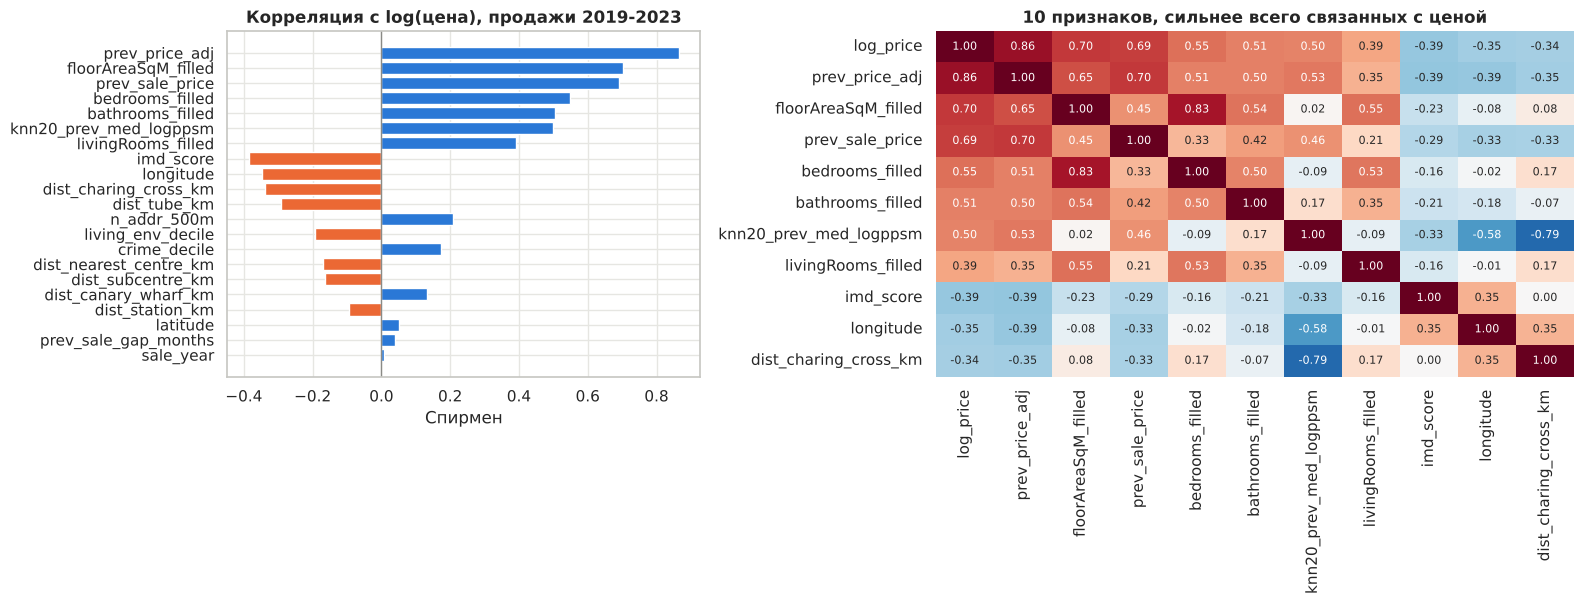

,prev_price_adj,floorAreaSqM_filled,prev_sale_price,bedrooms_filled,bathrooms_filled,knn20_prev_med_logppsm,livingRooms_filled,imd_score,longitude,dist_charing_cross_km,dist_tube_km,n_addr_500m,living_env_decile,crime_decile,dist_nearest_centre_km,dist_subcentre_km,dist_canary_wharf_km,dist_station_km,latitude,prev_sale_gap_months,sale_year
Спирмен с log(цена),0.860,0.700,0.690,0.550,0.510,0.500,0.390,-0.390,-0.350,-0.340,-0.290,0.210,-0.190,0.170,-0.170,-0.160,0.130,-0.100,0.050,0.040,0.010


In [30]:
num_feats = ['floorAreaSqM_filled', 'bedrooms_filled', 'bathrooms_filled', 'livingRooms_filled', 'latitude', 'longitude',
             'sale_year', 'prev_sale_price', 'prev_price_adj', 'prev_sale_gap_months', 'dist_charing_cross_km',
             'dist_canary_wharf_km', 'dist_nearest_centre_km', 'dist_subcentre_km', 'dist_station_km', 'dist_tube_km',
             'n_addr_500m', 'knn20_prev_med_logppsm', 'imd_score', 'crime_decile', 'living_env_decile']
cr = pp[['log_price'] + num_feats].corr(method='spearman')
target_corr = cr['log_price'].drop('log_price').sort_values(key=abs, ascending=False)
top = list(target_corr.index[:10])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={'width_ratios': [1, 1.35]})
axes[0].barh(target_corr.index, target_corr.values, color=[BLUE if v > 0 else ORANGE for v in target_corr.values])
axes[0].invert_yaxis(); axes[0].axvline(0, color=GRAY, lw=1)
axes[0].set_title('Корреляция с log(цена), продажи 2019-2023'); axes[0].set_xlabel('Спирмен')
sns.heatmap(cr.loc[['log_price'] + top, ['log_price'] + top], annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            ax=axes[1], annot_kws={'size': 8}, cbar=False)
axes[1].set_title('10 признаков, сильнее всего связанных с ценой')
plt.tight_layout(); plt.show()
display(target_corr.round(2).to_frame('Спирмен с log(цена)').T)

> **Что за график.** Слева корреляция Спирмена каждого числового признака с логарифмом цены (продажи 2019–2023 годов): синий — связь положительная, оранжевый — отрицательная. Справа таблица корреляций между 10 признаками, сильнее всего связанными с ценой.
> **Что показывает.** Сильнее всего с ценой связаны прошлая цена с поправкой на рост района (0,86), площадь (0,70) и прошлая цена как есть (0,69), затем комнаты и цены соседей (около 0,5). С IMD, долготой и расстоянием до центра связь отрицательная (от −0,34 до −0,39). Некоторые признаки сильно связаны между собой: площадь и спальни (0,83), цены соседей и расстояние до центра (−0,79). Часть информации в них дублируется, поэтому вклад признаков в прогноз мы проверяем абляцией (раздел 7.9), а не по корреляциям. Год продажи внутри 2019–2023 годов почти не связан с ценой (0,01): в эти годы рынок почти не рос (раздел 6.1).

### 7.7 Прошлая продажа адреса

Это самый полезный из новых признаков (раздел 7.9). Сравним нынешнюю цену с ценой прошлой продажи как есть и с поправкой на рост цен в районе. Поправка (`prev_price_adj`): прошлая цена умножается на то, во сколько раз за это время выросла медиана цены в почтовом районе (outcode).

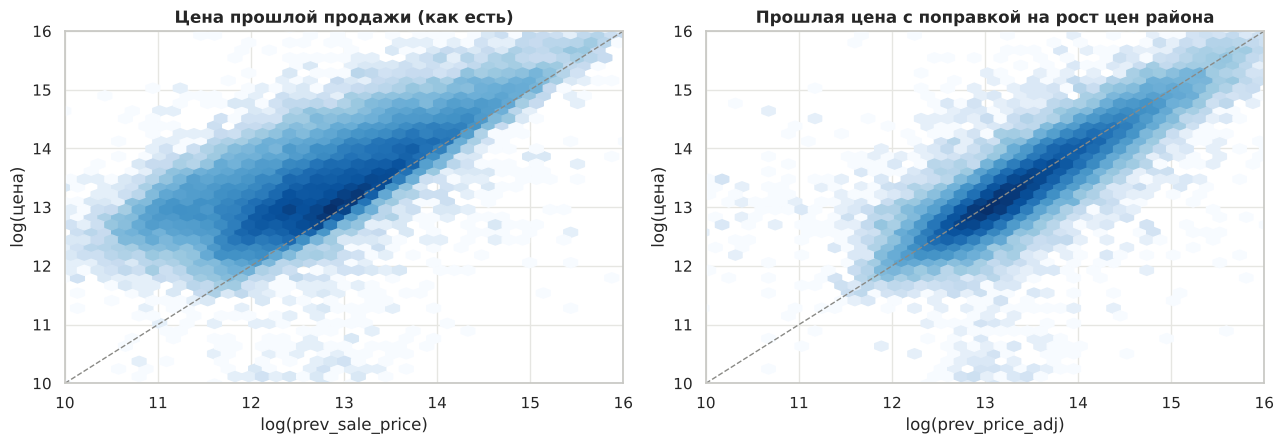

прошлая цена,"как есть, медиана ошибки %","с поправкой, медиана ошибки %"
все адреса,54.200,17.300
обычные адреса,54.800,17.100
addr_multi_unit = 1,41.100,22.700


In [31]:
rs = tr_e[(tr_e.sale_year >= 2019) & (tr_e.price_suspect == 0) & tr_e.prev_sale_price.notna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col, title in [(axes[0], 'prev_sale_price', 'Цена прошлой продажи (как есть)'),
                       (axes[1], 'prev_price_adj', 'Прошлая цена с поправкой на рост цен района')]:
    ax.hexbin(np.log(rs[col]), np.log(rs.price), gridsize=60, bins='log', cmap='Blues', mincnt=1)
    lim = [10, 16]; ax.plot(lim, lim, '--', color=GRAY, lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f'log({col})'); ax.set_ylabel('log(цена)'); ax.set_title(title)
plt.tight_layout(); plt.show()
err = pd.DataFrame({
    'как есть': (np.log(rs.price) - np.log(rs.prev_sale_price)).abs(),
    'с поправкой': (np.log(rs.price) - np.log(rs.prev_price_adj)).abs()})
mu = rs.addr_multi_unit == 1
summ = pd.DataFrame({'все адреса': err.median(), 'обычные адреса': err[~mu].median(), 'addr_multi_unit = 1': err[mu].median()})
display(((np.exp(summ) - 1) * 100).round(1).rename_axis('прошлая цена').T.rename(columns=lambda c: c + ', медиана ошибки %'))

> **Что за график.** По горизонтали логарифм прошлой цены (слева как есть, справа с поправкой), по вертикали логарифм нынешней цены, продажи 2019–2023 годов. Чем темнее, тем больше продаж. Пунктир — линия «цена равна прошлой».
> **Что показывает.** Прошлая цена как есть почти всегда ниже нынешней (точки выше пунктира), потому что рынок вырос. После поправки точки ложатся вдоль пунктира. Типичная ошибка, если угадывать цену по прошлой продаже, падает с 54% до 17%. У адресов с флагом `addr_multi_unit` ошибка с поправкой больше (23% против 17% у обычных адресов): там прошлая продажа часто относится к другой квартире. Поэтому флаг стоит дать модели.

### 7.8 Похожи ли train и test по новым признакам

Сравниваем последний год train (2023) с test (2024). KS (статистика Колмогорова–Смирнова) — наибольшая разница между долями значений в двух выборках: 0 означает, что распределения совпадают, 1 — что они совсем разные.

In [32]:
from scipy.stats import ks_2samp
tr23 = tr_e[tr_e.sale_year == 2023]
num = [c for cols in GROUPS.values() for c in cols if c != 'borough']
sh = []
for c in num:
    a, b = tr23[c].dropna(), te_e[c].dropna()
    sh.append({'признак': c, 'медиана train 2023': a.median(), 'медиана test 2024': b.median(),
               'пропусков train 2023, %': tr23[c].isna().mean() * 100, 'пропусков test, %': te_e[c].isna().mean() * 100,
               'KS': ks_2samp(a, b).statistic})
display(pd.DataFrame(sh).set_index('признак').round(3))
print('Районы (borough): в test %d районов, все есть в train: %s' %
      (te_e.borough.nunique(), set(te_e.borough.dropna()) <= set(tr_e.borough.dropna())))

,медиана train 2023,медиана test 2024,"пропусков train 2023, %","пропусков test, %",KS
признак,,,,,
prev_sale_price,"380,000.000","395,000.000",31.117,23.690,0.021
prev_price_adj,"596,444.444","572,248.840",31.117,23.720,0.035
prev_sale_gap_months,115.000,117.000,31.117,23.690,0.024
dist_charing_cross_km,8.737,8.594,0.000,0.000,0.029
dist_canary_wharf_km,9.958,10.174,0.000,0.000,0.026
dist_nearest_centre_km,6.662,6.791,0.000,0.000,0.017
dist_subcentre_km,1.662,1.589,0.000,0.000,0.033
dist_station_km,0.521,0.508,0.000,0.000,0.017
dist_tube_km,0.950,0.945,0.000,0.000,0.024


Районы (borough): в test 29 районов, все есть в train: True


**Вывод.** По всем новым признакам train 2023 и test 2024 похожи: KS не больше 0,07, медианы близки. Больше всего различается `n_addr_500m` (KS 0,07): в test немного больше продаж в менее плотных местах. Прошлая продажа в test пропущена реже (24% против 31%), IMD чуть чаще (8,5% против 7,7%). Все районы test есть в train, поэтому модели не встретятся незнакомые районы.

### 7.9 Какие признаки оставили и почему

Вклад каждой группы признаков проверяли **абляцией**: обучаем одну и ту же модель (градиентный бустинг `HistGradientBoostingRegressor`) с группой и без неё и сравниваем ошибку. Проверка только по времени: для каждого года Y из 2021, 2022, 2023 обучаемся на продажах до Y−1 и проверяем на Y. Признаки из цен для каждого года пересчитываются только по истории до Y−1, как для настоящего test. Ошибка — RMSE по логарифму цены (меньше — лучше). Грубо: RMSE 0,35 по логарифму означает, что прогноз часто ошибается на ±40% (e^0,35 ≈ 1,42). Код: `src/ablation.py`, результаты: `reports/ablation_multi_result.csv`.

год проверки,2021,2022,2023,среднее,изменение к базе
набор,,,,,
базовые столбцы,0.382,0.377,0.362,0.374,0.000
+ прошлая продажа адреса,0.370,0.360,0.340,0.357,-0.017
+ расстояния до центров,0.379,0.374,0.358,0.370,-0.003
+ индекс депривации IMD,0.380,0.374,0.358,0.371,-0.003
+ транспорт,0.381,0.376,0.360,0.372,-0.001
+ плотность и цены ближайших продаж,0.381,0.374,0.361,0.372,-0.001
+ район (borough),0.381,0.377,0.361,0.373,-0.001
+ ставка Банка Англии,0.382,0.379,0.366,0.376,0.002
+ цены района за прошлый год,0.386,0.378,0.366,0.376,0.003


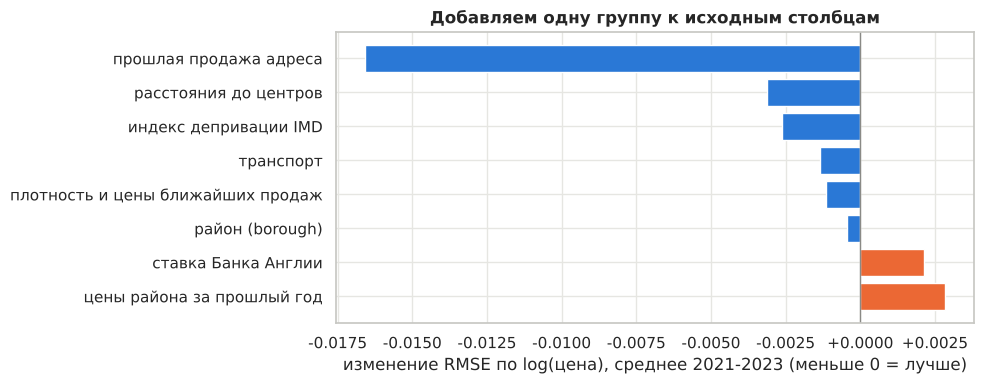

In [33]:
res_path = next((Path(d) / 'ablation_multi_result.csv' for d in ('reports', '../reports')
                 if (Path(d) / 'ablation_multi_result.csv').exists()), None)
if res_path is None:
    raise FileNotFoundError('Нет reports/ablation_multi_result.csv: python src/ablation.py --train data/processed/train_enriched.csv')
res = pd.read_csv(res_path)
pv = res.pivot_table(index='набор', columns='год проверки', values='RMSE')
pv['среднее'] = pv.mean(axis=1)
pv['изменение к базе'] = pv['среднее'] - pv.loc['базовые столбцы', 'среднее']
order = (['базовые столбцы'] + sorted([i for i in pv.index if i.startswith('+ ') and i != '+ все группы'],
                                      key=lambda i: pv.loc[i, 'среднее'])
         + ['+ все группы'] + sorted([i for i in pv.index if i.startswith('все, но без')], key=lambda i: pv.loc[i, 'среднее'])
         + [i for i in pv.index if i.startswith('итоговый')])
display(pv.loc[order].round(4))

one = pv.loc[[i for i in order if i.startswith('+ ') and i != '+ все группы'], 'изменение к базе'].sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([i[2:] for i in one.index], one.values, color=[BLUE if v < 0 else ORANGE for v in one.values])
ax.axvline(0, color=GRAY, lw=1); ax.invert_yaxis()
ax.set_title('Добавляем одну группу к исходным столбцам')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.4f}'))
ax.set_xlabel('изменение RMSE по log(цена), среднее 2021-2023 (меньше 0 = лучше)')
plt.tight_layout(); plt.show()

> **Что за график.** Насколько меняется ошибка, если добавить одну группу признаков к исходным столбцам (среднее по трём годам). Синий — ошибка уменьшилась (группа помогает), оранжевый — выросла.
> **Что показывает.** Главный выигрыш даёт **прошлая продажа адреса** (ошибка 0,357 против 0,374 у исходных столбцов). Расстояния до центров, IMD, транспорт, цены соседей и район помогают понемногу, но в каждом из трёх лет в одну сторону. **Ставка Банка Англии** и **цены района за прошлый год** ошибку увеличивают, поэтому их убрали.

**Итоговый набор** (15 признаков, список `KEEP` в `src/build_dataset.py`) даёт RMSE 0,353 в среднем по 2021–2023 годам против 0,374 у исходных столбцов, то есть ошибка меньше примерно на 5,5%. Это не хуже, чем со всеми группами сразу (0,355). Почему убраны остальные столбцы (дубли, сильно коррелированные признаки), описано в `FEATURES.md`.

Оговорки: разницы порядка 0,001–0,003 малы и могут быть шумом (доверительные интервалы не считались); модель здесь одна и без настройки, на чекпойнте 3 результаты могут сдвинуться.

## 8. Выводы и что делаем дальше

### 8.1 Что мы узнали о данных

- **Данные.** В train 266 325 продаж 1995–2023 годов, в test 16 547 продаж 2024 года (январь–август) без цены. Все объекты находятся в 167 почтовых районах Лондона.
- **Цена.** Сильно перекошена вправо: есть длинный хвост дорогих продаж. После логарифма распределение почти симметричное, поэтому предсказывать будем логарифм цены.
- **Пропуски.** В целом пустых ячеек 3,9%, но хотя бы один пропуск есть у 36% строк, поэтому строки не удаляем, а заполняем пропуски (медиана по типу жилья и спальням для площади, по типу для комнат, `Unknown` для категорий) с флагами «было пропущено».
- **Где пропуски.** Больше всего их в энергоклассе (21%), ванных (18%), гостиных (14%), спальнях (9%) и площади (5%). Комнаты пропускаются обычно вместе, а площадь чаще пропущена у редких названий типа жилья. В test площади пропущено больше (12% против 5,6% в train 2023 года).
- **Ошибки.** 19 названий типа жилья на самом деле означают 6 типов; есть 602 полных дубликата, 989 повторов «адрес + месяц» с разной ценой и явно неверные цены (например, около 99 млн £ за квартиру в 45 м²).
- **Выбросы.** Дорогие продажи в центре настоящие, их оставляем. Подозрительных значений цены за м² (меньше 300 £ или больше 40 000 £) всего 0,4% строк.
- **Цена по годам.** Медиана выросла с 77 тыс. £ (1995) до 561 тыс. £ (2023). С 2017 года цена за м² почти не растёт, а в 2023 году медиана цены на 3,3% ниже, чем в 2022.
- **Что влияет на цену.** Сильно влияют район (цена за м² различается в 5,6 раза: от 4 124 £ в SE28 до 23 076 £ в W1B), год продажи, площадь и число комнат. Форма собственности и энергокласс влияют слабее (заметно выше цена за м² только у классов A и B).
- **Площадь и цена за м².** Идея «чем больше площадь, тем ниже цена за м²» по этому анализу не подтвердилась и не опровергнута: до 85–100 м² цена за м² снижается, потом растёт. Район и тип жилья перемешаны с площадью, поэтому проверять нужно на модели.
- **Адреса.** Часть значений `fullAddress` — это адрес целого дома: у одного адреса до 112 продаж, а цена между продажами с интервалом 1–3 месяца отличается на 24%. Такие адреса (около 5% строк) помечены флагом `addr_multi_unit`.
- **Повторные продажи.** 64% адресов продавались больше одного раза, и цена очень похожа на цену прошлой продажи того же адреса (корреляция 0,79). 76% адресов из test есть в train. Это самый перспективный признак.

- **Основная база.** Собрана одной командой (`src/build_dataset.py`): исходные столбцы, флаги очистки (строки не удалены) и 15 новых признаков. Признаки из цен считаются только по прошлому и только по «чистым» продажам. С ними ошибка прогноза (RMSE по логарифму цены) снижается с 0,374 до 0,353; главный вклад даёт прошлая продажа адреса с поправкой на рост цен района. По новым признакам train 2023 и test 2024 похожи.

### 8.2 Что делаем дальше

1. **Цель.** Обучаем модель на логарифме цены. Цену за м² как цель пока не выбрали: площадь пропущена в 5% train и 12% test, и для этих строк цену за м² не посчитать без заполнения.
2. **Проверка модели только по времени.** Обучаемся на годах до N, проверяем на году N+1 (например, 2023). Случайное перемешивание недопустимо.
3. **Подготовка данных.** Типы жилья объединены, дубликаты и подозрительные значения помечены (раздел 7.1). Пропуски заполнены (раздел 7.2). Осталось решить, какие помеченные строки исключать из обучения, и сравнить модели на исходных столбцах с пропусками и на заполненных.
4. **Новые признаки.** Сделано (раздел 7). Дальше: заполнить пропуски IMD через таблицу соответствия кодов LSOA 2011 и 2021 годов, попробовать данные EPC (этаж, возраст дома).
5. **Первые модели.** Простой ориентир для сравнения (медиана цены района за прошлый год), затем градиентный бустинг (LightGBM или CatBoost) и сравнение с ней.

### 8.3 Ограничения анализа

- Единицы цены (фунты) и смысл `sale_month` и `sale_year` (дата продажи) мы вывели из названий столбцов и данных, описание соревнования на этот счёт не проверяли.
- Объяснения (например, что редкие названия типа пришли из другого источника) правдоподобны, но не доказаны. Причина резкого роста числа продаж после 2020 года неизвестна.
- Флаг `addr_multi_unit` ловит только явные случаи (две продажи в пределах 3 месяцев). Разные квартиры под одним адресом, видимо, встречаются и среди продаж с большим интервалом, но отличить их от настоящих перепродаж по данным нельзя.
- IMD 2019 — снимок на один год, а цены идут с 1995 года. Станции взяты из OpenStreetMap на сегодня; годы открытия новых станций добавлены вручную, закрытые станции не учтены.
- Корреляции показывают только то, что признаки меняются вместе, и не доказывают причину.
- Часть «ошибок» (очень низкие цены) может оказаться настоящими сделками (доли собственности, сделки между родственниками), отличить это по данным нельзя.